In [ ]:
import sys
# Paste the python code provided in the cell description and execute it

"""
Bulgarian net dynamic optimal-control rerun
==========================================
"""
from __future__ import annotations
import json
from pathlib import Path
import numpy as np
import pandas as pd

OUT_DIR = Path("bulgaria_net_rerun_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BNB_2023_2024 = {
    "D": 8030.6,
    "RE": 6544.9,
    "I": 661.6,
    "Y_FDI": 15237.1,
    "C_D_plus_I": 8692.2,
}
CHI_BNB_2023_2024 = BNB_2023_2024["C_D_plus_I"] / BNB_2023_2024["Y_FDI"]

BG_NA_2023_2024 = {
    "B1G_T": 174262.9,
    "P51C_T": 22885.2,
    "D1_T": 89021.2,
    "B1G_L68A": 10702.9,
    "P51C_L68A": 1177.3,
    "B1G_L68": 14504.8,
    "P51C_L68": 2130.4,
    "D1_L68": 816.0,
}

BG_NA_2023_2024["B1N_T"] = BG_NA_2023_2024["B1G_T"] - BG_NA_2023_2024["P51C_T"]
BG_NA_2023_2024["S_raw_N"] = BG_NA_2023_2024["B1N_T"] - BG_NA_2023_2024["D1_T"]
BG_NA_2023_2024["B1N_L68A"] = BG_NA_2023_2024["B1G_L68A"] - BG_NA_2023_2024["P51C_L68A"]
BG_NA_2023_2024["S_adj_N"] = BG_NA_2023_2024["S_raw_N"] - BG_NA_2023_2024["B1N_L68A"]
BG_NA_2023_2024["VA_adj_N"] = BG_NA_2023_2024["B1N_T"] - BG_NA_2023_2024["B1N_L68A"]
BG_NA_2023_2024["s_adj_N"] = BG_NA_2023_2024["S_adj_N"] / BG_NA_2023_2024["VA_adj_N"]
BG_NA_2023_2024["e_adj_N"] = BG_NA_2023_2024["S_adj_N"] / BG_NA_2023_2024["D1_T"]

BG_LEAK_BASE = {
    "chi": CHI_BNB_2023_2024,
    "sigma_ext_Y": BNB_2023_2024["Y_FDI"] / BG_NA_2023_2024["S_adj_N"],
    "sigma_ext_C": BNB_2023_2024["C_D_plus_I"] / BG_NA_2023_2024["S_adj_N"],
    "sigma_ext_RE": BNB_2023_2024["RE"] / BG_NA_2023_2024["S_adj_N"],
}

BG_NA_2023_2024["B1N_L68"] = BG_NA_2023_2024["B1G_L68"] - BG_NA_2023_2024["P51C_L68"]
BG_NA_2023_2024["B1N_L68B"] = BG_NA_2023_2024["B1N_L68"] - BG_NA_2023_2024["B1N_L68A"]
BG_NA_2023_2024["S_L68B_N"] = BG_NA_2023_2024["B1N_L68B"] - BG_NA_2023_2024["D1_L68"]
BG_NA_2023_2024["S_adj_N_excl_L68B"] = BG_NA_2023_2024["S_adj_N"] - BG_NA_2023_2024["S_L68B_N"]
BG_NA_2023_2024["VA_adj_N_excl_L68B"] = BG_NA_2023_2024["VA_adj_N"] - BG_NA_2023_2024["S_L68B_N"]
BG_NA_2023_2024["s_adj_N_excl_L68B"] = BG_NA_2023_2024["S_adj_N_excl_L68B"] / BG_NA_2023_2024["VA_adj_N_excl_L68B"]
BG_NA_2023_2024["e_adj_N_excl_L68B"] = BG_NA_2023_2024["S_adj_N_excl_L68B"] / BG_NA_2023_2024["D1_T"]

BG_LEAK_EXCL_L68B = {
    "chi": CHI_BNB_2023_2024,
    "sigma_ext_Y": BNB_2023_2024["Y_FDI"] / BG_NA_2023_2024["S_adj_N_excl_L68B"],
    "sigma_ext_C": BNB_2023_2024["C_D_plus_I"] / BG_NA_2023_2024["S_adj_N_excl_L68B"],
    "sigma_ext_RE": BNB_2023_2024["RE"] / BG_NA_2023_2024["S_adj_N_excl_L68B"],
}

BASE_DYNAMIC = {
    "a": 0.10,
    "theta": 0.65,
    "psi": 0.15,
    "omega": 0.50,
    "alpha": 0.40,
    "beta": 0.35,
    "gamma": 0.25,
    "delta": 0.95,
    "T_V0": 0.45,
    "eta": 0.30,
    "lambda0": 1.0,
    "T_sim": 30,
}

def make_params(calibration: dict, leakage: dict, sigma_R: float = 0.0, **overrides) -> dict:
    p = BASE_DYNAMIC.copy()
    p["s_adj"] = float(calibration["s_adj"])
    p["e_adj"] = float(calibration["e_adj"])
    p["chi"] = float(leakage["chi"])
    p["sigma_ext_Y"] = float(leakage["sigma_ext_Y"])
    p["sigma_ext_C"] = float(leakage["sigma_ext_C"])
    p["sigma_ext_RE"] = float(leakage["sigma_ext_RE"])
    p["sigma_R"] = float(sigma_R)
    p.update(overrides)
    p["Lambda_Y"] = p["sigma_R"] + p["sigma_ext_Y"]
    p["phi_Y"] = 1.0 - p["Lambda_Y"]
    p["Lambda_C"] = p["sigma_R"] + p["sigma_ext_C"]
    p["phi_C"] = 1.0 - p["Lambda_C"]
    if p["phi_Y"] <= 1e-12:
        raise ValueError("Infeasible leakage scenario: phi_Y <= 0.")
    if not (0.0 < p["s_adj"] < 1.0):
        raise ValueError("s_adj must be in (0,1).")
    if not np.isclose(p["s_adj"], p["e_adj"] / (1.0 + p["e_adj"]), rtol=0.0, atol=1e-8):
        raise AssertionError("s_adj and e_adj are inconsistent.")
    if not np.isclose(p["sigma_ext_C"] + p["sigma_ext_RE"], p["sigma_ext_Y"], rtol=0.0, atol=1e-10):
        raise AssertionError("External leakage decomposition does not close.")
    if p["sigma_ext_Y"] > 0.0:
        if not np.isclose(p["sigma_ext_C"], p["chi"] * p["sigma_ext_Y"], rtol=0.0, atol=1e-10):
            raise AssertionError("sigma_ext_C != chi * sigma_ext_Y.")
    return p

def baseline_calibration() -> dict:
    return {"s_adj": BG_NA_2023_2024["s_adj_N"], "e_adj": BG_NA_2023_2024["e_adj_N"]}

def excl_l68b_calibration() -> dict:
    return {"s_adj": BG_NA_2023_2024["s_adj_N_excl_L68B"], "e_adj": BG_NA_2023_2024["e_adj_N_excl_L68B"]}

def no_leakage_leakage_block() -> dict:
    return {"chi": CHI_BNB_2023_2024, "sigma_ext_Y": 0.0, "sigma_ext_C": 0.0, "sigma_ext_RE": 0.0}

def lambda_min(p: dict) -> float:
    val = (1.0 + p["e_adj"]) * p["T_V0"]
    if val <= 0.0:
        return 0.0
    return float(val ** (1.0 / p["eta"]))

def free_time_vec(lam, p: dict):
    lam = np.asarray(lam, dtype=float)
    return 1.0 - (1.0 + p["e_adj"]) * p["T_V0"] * np.power(lam, -p["eta"])

def utility_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(np.asarray(lam, dtype=float), np.asarray(tau, dtype=float))
    V = (1.0 - p["s_adj"]) * lam_b
    S_T = tau_b * p["phi_Y"] * p["s_adj"] * lam_b
    F = free_time_vec(lam_b, p)
    Omega = np.zeros(lam_b.shape, dtype=float)
    mask = (V > 0.0) & (S_T > 0.0) & (F > 0.0)
    Omega[mask] = np.power(V[mask], p["alpha"]) * np.power(S_T[mask], p["beta"]) * np.power(F[mask], p["gamma"])
    return Omega

def transition_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(np.asarray(lam, dtype=float), np.asarray(tau, dtype=float))
    bracket = (1.0 - tau_b) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 0.0)
    increment = p["a"] * np.power(p["s_adj"], p["theta"]) * np.power(bracket, p["theta"]) * np.power(lam_b, p["theta"] + p["psi"])
    return lam_b + increment

def build_grids(p: dict, n_lambda: int, n_tau: int, lam_max: float = 8.0):
    lmin = lambda_min(p)
    lam_start = max(1e-8, lmin * (1.0 + 1e-6))
    lam_max = max(float(lam_max), lam_start * 1.5, p["lambda0"] * 1.5)
    lam_grid = np.linspace(lam_start, lam_max, int(n_lambda))
    tau_grid = np.linspace(0.0, 1.0, int(n_tau))
    return lam_grid, tau_grid

def euler_residual(lam_grid, V, policy, p: dict):
    edge_order = 2 if lam_grid.size >= 3 else 1
    V_lambda = np.gradient(V, lam_grid, edge_order=edge_order)
    tau = policy
    Omega = utility_vec(lam_grid, tau, p)
    bracket = (1.0 - tau) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    eps = 1e-12
    dlam_dtau = -p["theta"] * p["a"] * np.power(p["s_adj"], p["theta"]) * p["phi_Y"] * np.power(np.maximum(bracket, eps), p["theta"] - 1.0) * np.power(lam_grid, p["theta"] + p["psi"])
    residual = np.zeros_like(Omega, dtype=float)
    interior = (tau > 1e-8) & (tau < 1.0 - 1e-8) & (Omega > 0.0) & (bracket > 1e-12)
    residual[interior] = p["beta"] * Omega[interior] / tau[interior] + p["delta"] * V_lambda[interior] * dlam_dtau[interior]
    return residual, interior, V_lambda

def solve_vfi(p: dict, n_lambda: int = 600, n_tau: int = 300, lam_max: float = 8.0, tol: float = 1e-9, max_iter: int = 10000):
    lam_grid, tau_grid = build_grids(p, n_lambda=n_lambda, n_tau=n_tau, lam_max=lam_max)
    Lam, Tau = np.meshgrid(lam_grid, tau_grid, indexing="ij")
    Omega = utility_vec(Lam, Tau, p)
    LamNext = transition_vec(Lam, Tau, p)
    boundary_above = int(np.count_nonzero(LamNext > lam_grid[-1]))
    boundary_below = int(np.count_nonzero(LamNext < lam_grid[0]))
    LamNext_clip = np.clip(LamNext, lam_grid[0], lam_grid[-1])
    V = np.zeros(lam_grid.shape, dtype=float)
    policy = np.zeros(lam_grid.shape, dtype=float)
    err = np.inf
    iterations = 0
    for iterations in range(1, max_iter + 1):
        V_next = np.interp(LamNext_clip.ravel(), lam_grid, V).reshape(Lam.shape)
        RHS = Omega + p["delta"] * V_next
        idx = np.argmax(RHS, axis=1)
        V_new = RHS[np.arange(lam_grid.size), idx]
        policy_new = tau_grid[idx]
        err = float(np.max(np.abs(V_new - V)))
        V = V_new
        policy = policy_new
        if err < tol:
            break
    residual, interior, V_lambda = euler_residual(lam_grid, V, policy, p)
    return {
        "params": p, "lam_grid": lam_grid, "tau_grid": tau_grid, "V": V, "policy": policy,
        "V_lambda": V_lambda, "euler_residual": residual, "interior": interior, "iterations": iterations,
        "vfi_error": err, "boundary_above_count": boundary_above, "boundary_below_count": boundary_below, "lambda_min": lambda_min(p)
    }

def simulate_path(p: dict, lam_grid, policy, V_lambda=None, T=None):
    T = int(p["T_sim"] if T is None else T)
    lam = float(p["lambda0"])
    if lam < lam_grid[0]:
        lam = float(lam_grid[0])
    rows = []
    welfare = 0.0
    identity_errors = []
    tvc_proxies = []
    for t in range(T + 1):
        tau = float(np.interp(lam, lam_grid, policy))
        tau = min(max(tau, 0.0), 1.0)
        S = p["s_adj"] * lam
        V = (1.0 - p["s_adj"]) * lam
        ST = tau * p["phi_Y"] * S
        Id = (1.0 - tau) * p["phi_Y"] * S
        R = p["sigma_R"] * S
        X = p["sigma_ext_C"] * S
        If = p["sigma_ext_RE"] * S
        F = float(free_time_vec(np.array([lam]), p)[0])
        Omega = float(utility_vec(np.array([lam]), np.array([tau]), p)[0])
        identity_error = abs(S - (R + X + If + ST + Id))
        identity_errors.append(identity_error)
        welfare += (p["delta"] ** t) * Omega
        if V_lambda is not None:
            Vl = float(np.interp(lam, lam_grid, V_lambda))
            tvc_proxies.append((p["delta"] ** t) * Vl * lam)
        lam_next = float(transition_vec(np.array([lam]), np.array([tau]), p)[0])
        rows.append({
            "t": t, "lambda": lam, "tau": tau, "S": S, "V": V, "S_T": ST, "I_d": Id,
            "R": R, "X_cash": X, "I_f_foreign_reinvestment": If, "F_free_time": F, "Omega": Omega,
            "identity_error": identity_error, "lambda_next": lam_next
        })
        lam = lam_next
    df = pd.DataFrame(rows)
    max_identity_error = float(max(identity_errors)) if identity_errors else np.nan
    max_tvc_proxy = float(max(tvc_proxies)) if tvc_proxies else np.nan
    return df, welfare, False, max_identity_error, tvc_proxies, max_tvc_proxy

def scenario_summary(label, p, sol, sim_df, welfare, projected, identity_error, tvc_max):
    last = sim_df.iloc[-1]
    first = sim_df.iloc[0]
    resid = sol["euler_residual"]
    interior = sol["interior"]
    if np.any(interior):
        euler_max_abs = float(np.max(np.abs(resid[interior])))
        euler_mean_abs = float(np.mean(np.abs(resid[interior])))
        n_interior = int(np.sum(interior))
    else:
        euler_max_abs, euler_mean_abs, n_interior = np.nan, np.nan, 0
    return {
        "label": label, "s_adj": p["s_adj"], "e_adj": p["e_adj"], "sigma_R": p["sigma_R"],
        "sigma_ext_Y": p["sigma_ext_Y"], "sigma_ext_C": p["sigma_ext_C"], "sigma_ext_RE": p["sigma_ext_RE"],
        "Lambda_Y": p["Lambda_Y"], "phi_Y": p["phi_Y"], "Lambda_C": p["Lambda_C"], "phi_C": p["phi_C"],
        "a": p["a"], "theta": p["theta"], "psi": p["psi"], "omega": p["omega"], "delta": p["delta"],
        "lambda_min": sol["lambda_min"], "lambda0_input": p["lambda0"], "lambda0_projected_to_grid": projected,
        "F0": float(first["F_free_time"]), "Omega0": float(first["Omega"]), "lambda_T": float(last["lambda"]),
        "tau_T": float(last["tau"]), "S_T_T": float(last["S_T"]), "V_T": float(last["V"]),
        "F_T": float(last["F_free_time"]), "Omega_T": float(last["Omega"]), "discounted_welfare": float(welfare),
        "identity_error_max": float(identity_error), "euler_max_abs_interior": euler_max_abs,
        "euler_mean_abs_interior": euler_mean_abs, "n_interior_policy_points": n_interior, "tvc_proxy_max": float(tvc_max),
        "vfi_iterations": int(sol["iterations"]), "vfi_error": float(sol["vfi_error"]), "boundary_above_count": int(sol["boundary_above_count"]),
        "boundary_below_count": int(sol["boundary_below_count"])
    }

def run_unit_tests():
    pass

def define_scenarios():
    return [
        {"label": "BG_net_baseline_external_only", "calibration": baseline_calibration(), "leakage": BG_LEAK_BASE, "sigma_R": 0.0},
        {"label": "BG_net_no_leakage_benchmark", "calibration": baseline_calibration(), "leakage": no_leakage_leakage_block(), "sigma_R": 0.0},
        {"label": "BG_net_rentier_005", "calibration": baseline_calibration(), "leakage": BG_LEAK_BASE, "sigma_R": 0.05},
        {"label": "BG_net_rentier_010", "calibration": baseline_calibration(), "leakage": BG_LEAK_BASE, "sigma_R": 0.10},
        {"label": "BG_net_excl_L68B_external_only", "calibration": excl_l68b_calibration(), "leakage": BG_LEAK_EXCL_L68B, "sigma_R": 0.0},
        {"label": "BG_net_excl_L68B_rentier_005", "calibration": excl_l68b_calibration(), "leakage": BG_LEAK_EXCL_L68B, "sigma_R": 0.05}
    ]

def run_scenario_list(scenarios, fast=False):
    n_lambda, n_tau, lam_max, tol, max_iter = (240, 120, 6.0, 1e-8, 3000) if fast else (600, 300, 8.0, 1e-9, 10000)
    rows, detailed = [], {}
    for sc in scenarios:
        p = make_params(sc["calibration"], sc["leakage"], sigma_R=sc["sigma_R"], **sc.get("overrides", {}))
        sol = solve_vfi(p, n_lambda=n_lambda, n_tau=n_tau, lam_max=lam_max, tol=tol, max_iter=max_iter)
        sim_df, welfare, projected, ident_err, _, tvc_max = simulate_path(p, sol["lam_grid"], sol["policy"], sol["V_lambda"])
        row = scenario_summary(sc["label"], p, sol, sim_df, welfare, projected, ident_err, tvc_max)
        rows.append(row)
        detailed[sc["label"]] = {"solution": sol, "simulation": sim_df, "params": p}
    return pd.DataFrame(rows), detailed

def run_rerun(fast=False):
    scenarios = define_scenarios()
    summary_df, detailed = run_scenario_list(scenarios, fast=fast)
    summary_df.to_csv(OUT_DIR / "scenario_summary.csv", index=False)

    base = summary_df.loc[summary_df["label"] == "BG_net_baseline_external_only"].iloc[0]
    no_leak = summary_df.loc[summary_df["label"] == "BG_net_no_leakage_benchmark"].iloc[0]

    welfare_loss_vs_no_leakage = 1.0 - base["discounted_welfare"] / no_leak["discounted_welfare"]
    productivity_gap = no_leak["lambda_T"] / base["lambda_T"] - 1.0

    comparison = pd.DataFrame([
        {"metric": "discounted_welfare", "baseline_external_only": base["discounted_welfare"], "no_leakage_benchmark": no_leak["discounted_welfare"], "baseline_loss_vs_no_leakage": welfare_loss_vs_no_leakage},
        {"metric": "lambda_T", "baseline_external_only": base["lambda_T"], "no_leakage_benchmark": no_leak["lambda_T"], "baseline_loss_vs_no_leakage": productivity_gap}
    ])
    comparison.to_csv(OUT_DIR / "welfare_comparison.csv", index=False)

    print("\nRerun outputs written to:", OUT_DIR.resolve())
    print("\nScenario summary:")
    display(summary_df[["label", "s_adj", "lambda_T", "discounted_welfare", "F_T", "vfi_iterations"]])
    print("\nWelfare comparison:")
    display(comparison)

run_rerun(fast=False)



Rerun outputs written to: /content/bulgaria_net_rerun_outputs

Scenario summary:


,label,s_adj,lambda_T,discounted_welfare,F_T,vfi_iterations
0,BG_net_baseline_external_only,0.372437,2.255087,6.448537,0.438169,421
1,BG_net_no_leakage_benchmark,0.372437,2.750968,7.256233,0.470691,423
2,BG_net_rentier_005,0.372437,2.148939,6.266206,0.429983,420
3,BG_net_rentier_010,0.372437,2.044368,6.080871,0.421388,420
4,BG_net_excl_L68B_external_only,0.363313,2.191310,6.432285,0.441433,421
5,BG_net_excl_L68B_rentier_005,0.363313,2.089057,6.250888,0.433368,420



Welfare comparison:


,metric,baseline_external_only,no_leakage_benchmark,baseline_loss_vs_no_leakage
0,discounted_welfare,6.448537,7.256233,0.111311
1,lambda_T,2.255087,2.750968,0.219894


In [ ]:
import sys
# Paste the python code provided in the cell description and execute it

"""
Bulgarian net dynamic model: numerical refinement and sensitivity analysis
==========================================================================
"""
from __future__ import annotations
import json
import math
from pathlib import Path
import numpy as np
import pandas as pd

OUT_DIR = Path("bulgaria_refinement_sensitivity_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BNB = {
    "2023": {
        "D": 3756.9,
        "RE": 4706.8,
        "I": 332.5,
        "Y_FDI": 8796.2,
        "C_D_plus_I": 4089.4,
    },
    "2024": {
        "D": 4273.7,
        "RE": 1838.1,
        "I": 329.1,
        "Y_FDI": 6440.9,
        "C_D_plus_I": 4602.8,
    },
    "2023_2024": {
        "D": 8030.6,
        "RE": 6544.9,
        "I": 661.6,
        "Y_FDI": 15237.1,
        "C_D_plus_I": 8692.2,
    },
}

for period, row in BNB.items():
    row["chi"] = row["C_D_plus_I"] / row["Y_FDI"]
    row["theta_RE"] = row["RE"] / row["Y_FDI"]
    if not np.isclose(row["D"] + row["RE"] + row["I"], row["Y_FDI"], rtol=0.0, atol=1e-8):
        raise AssertionError(f"BNB identity fails for {period}")
    if not np.isclose(row["D"] + row["I"], row["C_D_plus_I"], rtol=0.0, atol=1e-8):
        raise AssertionError(f"BNB cash identity fails for {period}")

BG_NA_RAW = {
    "2023": {
        "B1G_T": 82858.4,
        "P51C_T": 10898.1,
        "D1_T": 41374.6,
        "B1G_L68A": 5200.9,
        "P51C_L68A": 572.1,
        "B1G_L68": 7177.3,
        "P51C_L68": 1048.8,
        "D1_L68": 407.4,
    },
    "2024": {
        "B1G_T": 91404.5,
        "P51C_T": 11987.1,
        "D1_T": 47646.6,
        "B1G_L68A": 5502.0,
        "P51C_L68A": 605.2,
        "B1G_L68": 7327.5,
        "P51C_L68": 1081.6,
        "D1_L68": 408.6,
    },
    "2023_2024": {
        "B1G_T": 174262.9,
        "P51C_T": 22885.2,
        "D1_T": 89021.2,
        "B1G_L68A": 10702.9,
        "P51C_L68A": 1177.3,
        "B1G_L68": 14504.8,
        "P51C_L68": 2130.4,
        "D1_L68": 816.0,
    },
}

def build_calibration(period: str, exclude_l68b: bool = False) -> dict:
    row = BG_NA_RAW[period]
    B1N_T = row["B1G_T"] - row["P51C_T"]
    S_raw_N = B1N_T - row["D1_T"]
    B1N_L68A = row["B1G_L68A"] - row["P51C_L68A"]
    S_adj_N = S_raw_N - B1N_L68A
    VA_adj_N = B1N_T - B1N_L68A
    S_L68B_N = np.nan
    B1N_L68B = np.nan
    if exclude_l68b:
        B1N_L68 = row["B1G_L68"] - row["P51C_L68"]
        B1N_L68B = B1N_L68 - B1N_L68A
        D1_L68B = row["D1_L68"]
        S_L68B_N = B1N_L68B - D1_L68B
        S_adj_N = S_adj_N - S_L68B_N
        VA_adj_N = VA_adj_N - S_L68B_N
    if VA_adj_N <= 0 or row["D1_T"] <= 0 or S_adj_N <= 0:
        raise ValueError("Non-positive calibration aggregate.")
    s_adj = S_adj_N / VA_adj_N
    e_adj = S_adj_N / row["D1_T"]
    if not np.isclose(s_adj, e_adj / (1.0 + e_adj), rtol=0.0, atol=1e-10):
        raise AssertionError("Calibration s_adj/e_adj identity fails.")
    label = f"BG_{period}_net"
    if exclude_l68b:
        label += "_excl_L68B"
    return {
        "label": label, "period": period, "exclude_l68b": bool(exclude_l68b),
        "B1G_T": row["B1G_T"], "P51C_T": row["P51C_T"], "B1N_T": B1N_T, "D1_T": row["D1_T"],
        "S_raw_N": S_raw_N, "B1G_L68A": row["B1G_L68A"], "P51C_L68A": row["P51C_L68A"],
        "B1N_L68A": B1N_L68A, "B1N_L68B": B1N_L68B, "S_L68B_N": S_L68B_N, "S_adj_N": S_adj_N,
        "VA_adj_N": VA_adj_N, "s_adj": float(s_adj), "e_adj": float(e_adj),
    }

def build_leakage(cal: dict, period: str | None = None, sigma_R: float = 0.0) -> dict:
    if period is None:
        period = cal["period"]
    bnb = BNB[period]
    S_adj = cal["S_adj_N"]
    sigma_ext_Y = bnb["Y_FDI"] / S_adj
    sigma_ext_C = bnb["C_D_plus_I"] / S_adj
    sigma_ext_RE = bnb["RE"] / S_adj
    chi = bnb["chi"]
    if not np.isclose(sigma_ext_C + sigma_ext_RE, sigma_ext_Y, rtol=0.0, atol=1e-12):
        raise AssertionError("External leakage decomposition fails.")
    if not np.isclose(sigma_ext_C, chi * sigma_ext_Y, rtol=0.0, atol=1e-12):
        raise AssertionError("Cash leakage identity fails.")
    return {
        "period": period, "chi": float(chi), "sigma_ext_Y": float(sigma_ext_Y),
        "sigma_ext_C": float(sigma_ext_C), "sigma_ext_RE": float(sigma_ext_RE),
        "sigma_R": float(sigma_R), "D": bnb["D"], "RE": bnb["RE"], "I": bnb["I"],
        "Y_FDI": bnb["Y_FDI"], "C_D_plus_I": bnb["C_D_plus_I"],
    }

BASE_DYNAMIC = {
    "a": 0.10, "theta": 0.65, "psi": 0.15, "omega": 0.50,
    "alpha": 0.40, "beta": 0.35, "gamma": 0.25,
    "delta": 0.95, "T_V0": 0.45, "eta": 0.30,
    "lambda0": 1.0, "T_sim": 30,
}

def normalize_prefs(alpha: float, beta: float, gamma: float) -> tuple[float, float, float]:
    s = alpha + beta + gamma
    if s <= 0:
        raise ValueError("Preference weights must sum to a positive number.")
    return alpha / s, beta / s, gamma / s

def finalize_params(p: dict) -> dict:
    p = p.copy()
    p["alpha"], p["beta"], p["gamma"] = normalize_prefs(p["alpha"], p["beta"], p["gamma"])
    p["Lambda_Y"] = p["sigma_R"] + p["sigma_ext_Y"]
    p["phi_Y"] = 1.0 - p["Lambda_Y"]
    p["Lambda_C"] = p["sigma_R"] + p["sigma_ext_C"]
    p["phi_C"] = 1.0 - p["Lambda_C"]
    if p["phi_Y"] <= 1e-12:
        raise ValueError("Infeasible leakage scenario: phi_Y <= 0.")
    if not (0.0 < p["s_adj"] < 1.0):
        raise ValueError("s_adj must lie in (0,1).")
    if not np.isclose(p["s_adj"], p["e_adj"] / (1.0 + p["e_adj"]), rtol=0.0, atol=1e-8):
        raise AssertionError("s_adj and e_adj are inconsistent.")
    if not np.isclose(p["sigma_ext_C"] + p["sigma_ext_RE"], p["sigma_ext_Y"], rtol=0.0, atol=1e-10):
        raise AssertionError("External leakage decomposition does not close.")
    if p["sigma_ext_Y"] > 0.0:
        if not np.isclose(p["sigma_ext_C"], p["chi"] * p["sigma_ext_Y"], rtol=0.0, atol=1e-10):
            raise AssertionError("sigma_ext_C != chi * sigma_ext_Y.")
    return p

def make_params(cal: dict, leak: dict, sigma_R: float = 0.0, **overrides) -> dict:
    p = BASE_DYNAMIC.copy()
    p["s_adj"] = float(cal["s_adj"])
    p["e_adj"] = float(cal["e_adj"])
    p["chi"] = float(leak["chi"])
    p["sigma_ext_Y"] = float(leak["sigma_ext_Y"])
    p["sigma_ext_C"] = float(leak["sigma_ext_C"])
    p["sigma_ext_RE"] = float(leak["sigma_ext_RE"])
    p["sigma_R"] = float(sigma_R)
    p.update(overrides)
    return finalize_params(p)

def apply_overrides(base_p: dict, **overrides) -> dict:
    p = base_p.copy()
    p.update(overrides)
    return finalize_params(p)

def no_leak_params(p: dict) -> dict:
    p0 = p.copy()
    p0["sigma_R"] = 0.0
    p0["sigma_ext_Y"] = 0.0
    p0["sigma_ext_C"] = 0.0
    p0["sigma_ext_RE"] = 0.0
    return finalize_params(p0)

def lambda_min(p: dict) -> float:
    val = (1.0 + p["e_adj"]) * p["T_V0"]
    if val <= 0.0:
        return 0.0
    return float(val ** (1.0 / p["eta"]))

def free_time_vec(lam, p: dict):
    lam = np.asarray(lam, dtype=float)
    return 1.0 - (1.0 + p["e_adj"]) * p["T_V0"] * np.power(lam, -p["eta"])

def utility_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(np.asarray(lam, dtype=float), np.asarray(tau, dtype=float))
    V = (1.0 - p["s_adj"]) * lam_b
    S_T = tau_b * p["phi_Y"] * p["s_adj"] * lam_b
    F = free_time_vec(lam_b, p)
    out = np.zeros(lam_b.shape, dtype=float)
    mask = (V > 0.0) & (S_T > 0.0) & (F > 0.0)
    out[mask] = np.power(V[mask], p["alpha"]) * np.power(S_T[mask], p["beta"]) * np.power(F[mask], p["gamma"])
    return out

def transition_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(np.asarray(lam, dtype=float), np.asarray(tau, dtype=float))
    bracket = (1.0 - tau_b) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 0.0)
    increment = p["a"] * np.power(p["s_adj"], p["theta"]) * np.power(bracket, p["theta"]) * np.power(lam_b, p["theta"] + p["psi"])
    return lam_b + increment

def dtransition_dtau_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(np.asarray(lam, dtype=float), np.asarray(tau, dtype=float))
    bracket = (1.0 - tau_b) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 1e-12)
    return -p["theta"] * p["a"] * np.power(p["s_adj"], p["theta"]) * p["phi_Y"] * np.power(bracket, p["theta"] - 1.0) * np.power(lam_b, p["theta"] + p["psi"])

def utility_scalar(lam: float, tau: float, p: dict) -> float:
    V = (1.0 - p["s_adj"]) * lam
    S_T = tau * p["phi_Y"] * p["s_adj"] * lam
    F = 1.0 - (1.0 + p["e_adj"]) * p["T_V0"] * (lam ** (-p["eta"]))
    if V <= 0.0 or S_T <= 0.0 or F <= 0.0:
        return 0.0
    val = (V ** p["alpha"]) * (S_T ** p["beta"]) * (F ** p["gamma"])
    return float(val) if np.isfinite(val) else 0.0

def transition_scalar(lam: float, tau: float, p: dict) -> float:
    bracket = (1.0 - tau) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = max(bracket, 0.0)
    increment = p["a"] * (p["s_adj"] ** p["theta"]) * (bracket ** p["theta"]) * (lam ** (p["theta"] + p["psi"]))
    val = lam + increment
    return float(val) if np.isfinite(val) else lam

def build_log_lambda_grid(p: dict, n_lambda: int, lam_max: float) -> np.ndarray:
    lmin = lambda_min(p)
    lo = max(1e-8, lmin * (1.0 + 1e-8))
    hi = max(float(lam_max), lo * 1.5, p["lambda0"] * 1.5)
    return np.exp(np.linspace(np.log(lo), np.log(hi), int(n_lambda)))

def solve_vfi_grid(p: dict, n_lambda: int = 700, n_tau: int = 301, lam_max: float = 12.0, tol: float = 1e-10, max_iter: int = 8000):
    lam_grid = build_log_lambda_grid(p, n_lambda=n_lambda, lam_max=lam_max)
    tau_grid = np.linspace(0.0, 1.0, int(n_tau))
    Lam, Tau = np.meshgrid(lam_grid, tau_grid, indexing="ij")
    Omega = utility_vec(Lam, Tau, p)
    LamNext = transition_vec(Lam, Tau, p)
    boundary_above = int(np.count_nonzero(LamNext > lam_grid[-1]))
    boundary_below = int(np.count_nonzero(LamNext < lam_grid[0]))
    total_pairs = LamNext.size
    LamNext_clip = np.clip(LamNext, lam_grid[0], lam_grid[-1])
    V = np.zeros(lam_grid.shape, dtype=float)
    policy = np.full(lam_grid.shape, 0.5, dtype=float)
    err = np.inf
    policy_err = np.inf
    iterations = 0
    for iterations in range(1, max_iter + 1):
        V_next = np.interp(LamNext_clip.ravel(), lam_grid, V).reshape(Lam.shape)
        RHS = Omega + p["delta"] * V_next
        idx = np.argmax(RHS, axis=1)
        V_new = RHS[np.arange(lam_grid.size), idx]
        policy_new = tau_grid[idx]
        err = float(np.max(np.abs(V_new - V)))
        policy_err = float(np.max(np.abs(policy_new - policy)))
        V = V_new
        policy = policy_new
        if err < tol and policy_err < tol:
            break
    return {
        "lam_grid": lam_grid, "tau_grid": tau_grid, "V": V, "policy": policy,
        "iterations": iterations, "vfi_error": err, "policy_error": policy_err,
        "boundary_above_count": boundary_above, "boundary_below_count": boundary_below,
        "total_grid_pairs": int(total_pairs), "clipping_fraction": float((boundary_above + boundary_below) / max(total_pairs, 1)),
        "lambda_min": lambda_min(p),
    }

def golden_section_max(f, a: float, b: float, tol: float = 1e-10, max_iter: int = 80):
    gr = (math.sqrt(5.0) - 1.0) / 2.0
    c = b - gr * (b - a)
    d = a + gr * (b - a)
    fc = f(c)
    fd = f(d)
    for _ in range(max_iter):
        if abs(b - a) < tol:
            break
        if fc > fd:
            b = d
            d = c
            fd = fc
            c = b - gr * (b - a)
            fc = f(c)
        else:
            a = c
            c = d
            fc = fd
            d = a + gr * (b - a)
            fd = f(d)
    x = 0.5 * (a + b)
    fx = f(x)
    if not np.isfinite(fx):
        x = 0.5 * (a + b)
        fx = f(x)
    return float(x), float(fx) if np.isfinite(fx) else 0.0

def policy_refine_once(p: dict, lam_grid: np.ndarray, V: np.ndarray):
    tau_ref = np.empty_like(lam_grid)
    V_ref = np.empty_like(lam_grid)
    delta = p["delta"]
    for i, lam_i in enumerate(lam_grid):
        def obj(tau: float) -> float:
            lam_next = transition_scalar(float(lam_i), float(tau), p)
            V_next = float(np.interp(lam_next, lam_grid, V))
            val = utility_scalar(float(lam_i), float(tau), p) + delta * V_next
            return val if np.isfinite(val) else -1e100
        tau_star, V_star = golden_section_max(obj, 0.0, 1.0, tol=1e-10, max_iter=80)
        tau_ref[i] = tau_star
        V_ref[i] = V_star
    return V_ref, tau_ref

def policy_refine_multiple(p: dict, lam_grid: np.ndarray, V: np.ndarray, n_iter: int = 1):
    policy = None
    for _ in range(max(1, int(n_iter))):
        V, policy = policy_refine_once(p, lam_grid, V)
    return V, policy

def compute_diagnostics(p: dict, lam_grid: np.ndarray, V: np.ndarray, policy: np.ndarray):
    if lam_grid.size >= 3:
        loglam = np.log(lam_grid)
        dV_dlog = np.gradient(V, loglam, edge_order=2)
    else:
        loglam = np.log(lam_grid)
        dV_dlog = np.gradient(V, loglam)
    V_lambda = dV_dlog / lam_grid
    Omega = utility_vec(lam_grid, policy, p)
    lam_next = transition_vec(lam_grid, policy, p)
    dlam_dtau = dtransition_dtau_vec(lam_grid, policy, p)
    term1 = p["beta"] * Omega / np.maximum(policy, 1e-12)
    term2 = p["delta"] * V_lambda * dlam_dtau
    resid = term1 + term2
    denom = np.abs(term1) + np.abs(term2) + 1e-12
    resid_norm = np.abs(resid) / denom
    interior = (policy > 1e-6) & (policy < 1.0 - 1e-6) & (Omega > 0.0) & (lam_next > lam_grid[0]) & (lam_next < lam_grid[-1])
    if np.any(interior):
        euler_max_abs = float(np.max(np.abs(resid[interior])))
        euler_mean_abs = float(np.mean(np.abs(resid[interior])))
        euler_max_norm = float(np.max(resid_norm[interior]))
        euler_mean_norm = float(np.mean(resid_norm[interior]))
        n_interior = int(np.sum(interior))
    else:
        euler_max_abs, euler_mean_abs, euler_max_norm, euler_mean_norm, n_interior = np.nan, np.nan, np.nan, np.nan, 0
    bracket = (1.0 - policy) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 1e-12)
    marginal_product = p["a"] * p["theta"] * np.power(p["s_adj"], p["theta"]) * np.power(bracket, p["theta"] - 1.0) * np.power(lam_grid, p["theta"] + p["psi"])
    tvc_heuristic = p["delta"] * V_lambda * marginal_product
    return {
        "V_lambda": V_lambda, "euler_residual": resid, "euler_residual_norm": resid_norm, "interior": interior,
        "euler_max_abs": euler_max_abs, "euler_mean_abs": euler_mean_abs, "euler_max_norm": euler_max_norm,
        "euler_mean_norm": euler_mean_norm, "n_interior_policy_points": n_interior,
        "tvc_heuristic_max": float(np.max(tvc_heuristic)) if tvc_heuristic.size else np.nan,
        "tvc_heuristic_min": float(np.min(tvc_heuristic)) if tvc_heuristic.size else np.nan, "lambda_min": lambda_min(p),
    }

def simulate_path(p: dict, lam_grid: np.ndarray, policy: np.ndarray, T: int | None = None):
    T = int(p["T_sim"] if T is None else T)
    lam = float(p["lambda0"])
    projected = lam < lam_grid[0]
    if projected:
        lam = float(lam_grid[0])
    rows, identity_errors, path_clipped, feasible = [], [], 0, True
    for t in range(T + 1):
        tau = float(np.interp(lam, lam_grid, policy))
        tau = min(max(tau, 0.0), 1.0)
        S = p["s_adj"] * lam
        V = (1.0 - p["s_adj"]) * lam
        S_T = tau * p["phi_Y"] * S
        I_d = (1.0 - tau) * p["phi_Y"] * S
        R = p["sigma_R"] * S
        X = p["sigma_ext_C"] * S
        I_f = p["sigma_ext_RE"] * S
        F = float(free_time_vec(np.array([lam]), p)[0])
        Omega = float(utility_vec(np.array([lam]), np.array([tau]), p)[0])
        if F <= 1e-12:
            feasible = False
        identity_error = abs(S - (R + X + I_f + S_T + I_d))
        identity_errors.append(identity_error)
        welfare = (p["delta"] ** t) * Omega
        lam_next = float(transition_vec(np.array([lam]), np.array([tau]), p)[0])
        if lam_next > lam_grid[-1] or lam_next < lam_grid[0]:
            path_clipped += 1
        rows.append({
            "t": t, "lambda": lam, "tau": tau, "S": S, "V": V, "S_T": S_T, "I_d": I_d,
            "R": R, "X_cash": X, "I_f_foreign_reinvestment": I_f, "F_free_time": F, "Omega": Omega,
            "identity_error": identity_error, "lambda_next": lam_next
        })
        lam = lam_next
    df = pd.DataFrame(rows)
    max_identity_error = float(max(identity_errors)) if identity_errors else np.nan
    return df, float(df["Omega"].dot(p["delta"] ** df["t"])), projected, max_identity_error, feasible, int(path_clipped)

def default_settings(fast: bool, refine: bool) -> dict:
    if fast:
        return {
            "n_lambda": 260, "n_tau": 131, "lam_max": 8.0, "tol": 1e-8, "max_iter": 3000,
            "refine": False, "refine_iter": 0
        }
    else:
        return {
            "n_lambda": 700, "n_tau": 301, "lam_max": 12.0, "tol": 1e-10, "max_iter": 8000,
            "refine": bool(refine), "refine_iter": 1 if refine else 0
        }

def run_single(label: str, p: dict, fast: bool = False, refine: bool = True, settings: dict | None = None):
    st = settings or default_settings(fast=fast, refine=refine)
    sol = solve_vfi_grid(p, n_lambda=st["n_lambda"], n_tau=st["n_tau"], lam_max=st["lam_max"], tol=st["tol"], max_iter=st["max_iter"])
    lam_grid, V, policy = sol["lam_grid"], sol["V"], sol["policy"]
    if st.get("refine", False) and st.get("refine_iter", 0) > 0:
        V, policy = policy_refine_multiple(p, lam_grid, V, n_iter=int(st["refine_iter"]))
    diag = compute_diagnostics(p, lam_grid, V, policy)
    sim, welfare, projected, ident_err, feasible, path_clipped = simulate_path(p, lam_grid, policy)
    last = sim.iloc[-1]
    first = sim.iloc[0]
    summary = {
        "label": label, "s_adj": p["s_adj"], "e_adj": p["e_adj"], "sigma_R": p["sigma_R"],
        "sigma_ext_Y": p["sigma_ext_Y"], "sigma_ext_C": p["sigma_ext_C"], "sigma_ext_RE": p["sigma_ext_RE"], "chi": p["chi"],
        "Lambda_Y": p["Lambda_Y"], "phi_Y": p["phi_Y"], "Lambda_C": p["Lambda_C"], "phi_C": p["phi_C"],
        "a": p["a"], "theta": p["theta"], "psi": p["psi"], "omega": p["omega"], "alpha": p["alpha"], "beta": p["beta"],
        "gamma": p["gamma"], "delta": p["delta"], "T_V0": p["T_V0"], "eta": p["eta"], "lambda_min": diag["lambda_min"],
        "lambda0_input": p["lambda0"], "lambda0_projected_to_grid": projected, "F0": float(first["F_free_time"]),
        "Omega0": float(first["Omega"]), "lambda_T": float(last["lambda"]), "tau_T": float(last["tau"]),
        "S_T_T": float(last["S_T"]), "V_T": float(last["V"]), "F_T": float(last["F_free_time"]),
        "Omega_T": float(last["Omega"]), "discounted_welfare": float(welfare), "identity_error_max": float(ident_err),
        "feasible": bool(feasible), "path_clipped_count": int(path_clipped), "euler_max_abs": diag["euler_max_abs"],
        "euler_mean_abs": diag["euler_mean_abs"], "euler_max_norm": diag["euler_max_norm"], "euler_mean_norm": diag["euler_mean_norm"],
        "n_interior_policy_points": diag["n_interior_policy_points"], "tvc_heuristic_max": diag["tvc_heuristic_max"],
        "tvc_heuristic_min": diag["tvc_heuristic_min"], "vfi_iterations": int(sol["iterations"]),
        "vfi_error": float(sol["vfi_error"]), "policy_error": float(sol["policy_error"]), "boundary_above_count": int(sol["boundary_above_count"]),
        "boundary_below_count": int(sol["boundary_below_count"]), "clipping_fraction": float(sol["clipping_fraction"]),
        "n_lambda": int(st["n_lambda"]), "n_tau": int(st["n_tau"]), "lam_max": float(st["lam_max"]), "refined": bool(st.get("refine", False)),
    }
    obj = {
        "params": p, "lam_grid": lam_grid, "V": V, "policy": policy, "V_lambda": diag["V_lambda"],
        "euler_residual": diag["euler_residual"], "euler_residual_norm": diag["euler_residual_norm"], "interior": diag["interior"],
        "diagnostics": diag, "simulation": sim, "settings": st,
    }
    return summary, sim, obj

def prefix_dict(d: dict, prefix: str) -> dict:
    return {f"{prefix}{k}": v for k, v in d.items() if k != "label"}

def run_pair(label: str, p: dict, meta: dict | None = None, fast: bool = False, refine: bool = True, settings: dict | None = None, store: bool = False):
    leak_summary, leak_sim, leak_obj = run_single(f"{label}_leak", p, fast=fast, refine=refine, settings=settings)
    p0 = no_leak_params(p)
    nol_summary, nol_sim, nol_obj = run_single(f"{label}_noleak", p0, fast=fast, refine=refine, settings=settings)
    row = {"label": label}
    row.update(meta or {})
    row.update(prefix_dict(leak_summary, "leak_"))
    row.update(prefix_dict(nol_summary, "noleak_"))
    W_leak = leak_summary["discounted_welfare"]
    W_nol = nol_summary["discounted_welfare"]
    lam_leak = leak_summary["lambda_T"]
    lam_nol = nol_summary["lambda_T"]
    row["welfare_loss"] = 1.0 - W_leak / W_nol if W_nol > 0 else np.nan
    row["lambda_gap_no_leak_over_leak"] = lam_nol / lam_leak - 1.0 if lam_leak > 0 else np.nan
    row["lambda_shortfall"] = 1.0 - lam_leak / lam_nol if lam_nol > 0 else np.nan
    row["terminal_utility_loss"] = 1.0 - leak_summary["Omega_T"] / nol_summary["Omega_T"] if nol_summary["Omega_T"] > 0 else np.nan
    row["social_wage_terminal_loss"] = 1.0 - leak_summary["S_T_T"] / nol_summary["S_T_T"] if nol_summary["S_T_T"] > 0 else np.nan
    row["private_consumption_terminal_loss"] = 1.0 - leak_summary["V_T"] / nol_summary["V_T"] if nol_summary["V_T"] > 0 else np.nan
    row["free_time_terminal_loss"] = 1.0 - leak_summary["F_T"] / nol_summary["F_T"] if nol_summary["F_T"] > 0 else np.nan
    row["feasible_pair"] = bool(leak_summary["feasible"] and nol_summary["feasible"])
    if store:
        return row, leak_sim, nol_sim, leak_obj, nol_obj
    return row, None, None, None, None

PARAM_RANGES = {
    "a": [0.06, 0.10, 0.16],
    "theta": [0.55, 0.65, 0.75],
    "psi": [0.00, 0.15, 0.30],
    "omega": [0.00, 0.50, 1.00],
    "delta": [0.90, 0.95, 0.98],
    "alpha": [0.30, 0.40, 0.50],
    "beta": [0.25, 0.35, 0.45],
    "gamma": [0.15, 0.25, 0.35],
    "T_V0": [0.35, 0.45, 0.55],
    "eta": [0.20, 0.30, 0.40],
}
SIGMA_R_VALUES = [0.00, 0.05, 0.10]

def calibration_variants() -> list[tuple[str, dict, dict]]:
    variants = []
    for period in ["2023", "2024", "2023_2024"]:
        cal = build_calibration(period, exclude_l68b=False)
        leak = build_leakage(cal, period=period, sigma_R=0.0)
        variants.append((cal["label"], cal, leak))
    cal_excl = build_calibration("2023_2024", exclude_l68b=True)
    leak_excl = build_leakage(cal_excl, period="2023_2024", sigma_R=0.0)
    variants.append((cal_excl["label"], cal_excl, leak_excl))
    return variants

def run_calibration_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []
    for name, cal, leak in calibration_variants():
        p = make_params(cal, leak, sigma_R=0.0)
        meta = {
            "sensitivity_type": "calibration", "calibration_label": name, "period": cal["period"],
            "exclude_l68b": cal["exclude_l68b"], "S_adj_N": cal["S_adj_N"], "VA_adj_N": cal["VA_adj_N"],
            "s_adj": cal["s_adj"], "e_adj": cal["e_adj"], "sigma_ext_Y": leak["sigma_ext_Y"], "chi": leak["chi"],
        }
        row, _, _, _, _ = run_pair(f"cal_{name}", p, meta=meta, fast=fast, refine=refine)
        rows.append(row)
    return pd.DataFrame(rows)

def run_oat_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []
    for param, values in PARAM_RANGES.items():
        for val in values:
            p = apply_overrides(base_p, **{param: val})
            meta = {"sensitivity_type": "oat", "sensitivity_parameter": param, "sensitivity_value": val}
            row, _, _, _, _ = run_pair(f"oat_{param}_{val}", p, meta=meta, fast=fast, refine=refine)
            rows.append(row)
    return pd.DataFrame(rows)

def run_sigma_R_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []
    external_only_welfare = None
    for sr in SIGMA_R_VALUES:
        p = apply_overrides(base_p, sigma_R=sr)
        meta = {"sensitivity_type": "sigma_R", "sensitivity_parameter": "sigma_R", "sensitivity_value": sr}
        row, _, _, _, _ = run_pair(f"sigma_R_{sr}", p, meta=meta, fast=fast, refine=refine)
        if sr == 0.0:
            external_only_welfare = row["leak_discounted_welfare"]
        if external_only_welfare is not None and external_only_welfare > 0:
            row["incremental_rentier_welfare_loss_vs_external_only"] = 1.0 - row["leak_discounted_welfare"] / external_only_welfare
        else:
            row["incremental_rentier_welfare_loss_vs_external_only"] = np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def run_grid_convergence(base_p: dict, fast: bool = False):
    specs = [
        {"name": "coarse", "n_lambda": 300, "n_tau": 151, "lam_max": 8.0, "tol": 1e-8, "max_iter": 3000, "refine": False, "refine_iter": 0},
        {"name": "medium", "n_lambda": 600, "n_tau": 301, "lam_max": 10.0, "tol": 1e-9, "max_iter": 5000, "refine": True, "refine_iter": 1}
    ]
    rows = []
    for st in specs:
        settings = {
            "n_lambda": st["n_lambda"], "n_tau": st["n_tau"], "lam_max": st["lam_max"],
            "tol": st["tol"], "max_iter": st["max_iter"], "refine": st["refine"], "refine_iter": st["refine_iter"]
        }
        row, _, _, _, _ = run_pair(
            f"grid_{st['name']}", base_p,
            meta={
                "sensitivity_type": "grid_convergence", "grid_name": st["name"],
                "n_lambda": st["n_lambda"], "n_tau": st["n_tau"], "lam_max": st["lam_max"], "refined": st["refine"]
            },
            fast=False, refine=st["refine"], settings=settings
        )
        rows.append(row)
    return pd.DataFrame(rows)

def acceptance_report(df: pd.DataFrame) -> pd.DataFrame:
    checks = []
    def add_check(name: str, passed: bool, value, threshold):
        checks.append({"check": name, "passed": bool(passed), "value": value, "threshold": threshold})
    if "leak_euler_max_norm" in df.columns:
        val = float(np.nanmax(df["leak_euler_max_norm"].values))
        add_check("baseline_leak_euler_max_norm_below_5e-3", val < 5e-3, val, 5e-3)
    if "leak_clipping_fraction" in df.columns:
        val = float(np.nanmax(df["leak_clipping_fraction"].values))
        add_check("baseline_leak_clipping_fraction_below_1e-3", val < 1e-3, val, 1e-3)
    if "leak_identity_error_max" in df.columns:
        val = float(np.nanmax(df["leak_identity_error_max"].values))
        add_check("baseline_leak_identity_error_below_1e-12", val < 1e-12, val, 1e-12)
    if "leak_vfi_error" in df.columns:
        val = float(np.nanmax(df["leak_vfi_error"].values))
        add_check("baseline_leak_vfi_error_below_1e-10", val < 1e-10, val, 1e-10)
    if "feasible_pair" in df.columns:
        val = bool(np.all(df["feasible_pair"].values))
        add_check("all_scenarios_feasible", val, val, True)
    return pd.DataFrame(checks)

def run_all(fast: bool = True, refine: bool = True, do_grid: bool = True, do_calibration: bool = True, do_oat: bool = True, do_sigma_R: bool = True):
    base_cal = build_calibration("2023_2024", exclude_l68b=False)
    base_leak = build_leakage(base_cal, period="2023_2024", sigma_R=0.0)
    base_p = make_params(base_cal, base_leak, sigma_R=0.0)

    base_row, base_leak_sim, base_nol_sim, base_leak_obj, base_nol_obj = run_pair(
        "baseline_BG_net_external_only", base_p,
        meta={
            "sensitivity_type": "baseline", "calibration_label": base_cal["label"],
            "period": base_cal["period"], "exclude_l68b": base_cal["exclude_l68b"],
        },
        fast=fast, refine=refine, store=True
    )
    base_df = pd.DataFrame([base_row])
    base_df.to_csv(OUT_DIR / "baseline_pair_summary.csv", index=False)
    base_leak_sim.to_csv(OUT_DIR / "baseline_leak_simulation.csv", index=False)
    base_nol_sim.to_csv(OUT_DIR / "baseline_noleak_simulation.csv", index=False)

    all_frames = {"baseline": base_df}
    if do_grid:
        grid_df = run_grid_convergence(base_p, fast=fast)
        grid_df.to_csv(OUT_DIR / "grid_convergence.csv", index=False)
        all_frames["grid"] = grid_df
    if do_calibration:
        cal_df = run_calibration_sensitivity(base_p, fast=fast, refine=refine)
        cal_df.to_csv(OUT_DIR / "calibration_sensitivity.csv", index=False)
        all_frames["calibration"] = cal_df
    if do_oat:
        oat_df = run_oat_sensitivity(base_p, fast=fast, refine=refine)
        oat_df.to_csv(OUT_DIR / "oat_sensitivity.csv", index=False)
        all_frames["oat"] = oat_df
    if do_sigma_R:
        sr_df = run_sigma_R_sensitivity(base_p, fast=fast, refine=refine)
        sr_df.to_csv(OUT_DIR / "sigma_R_sensitivity.csv", index=False)
        all_frames["sigma_R"] = sr_df

    combined = pd.concat([v for v in all_frames.values() if isinstance(v, pd.DataFrame)], ignore_index=True)
    acc = acceptance_report(combined)
    acc.to_csv(OUT_DIR / "acceptance_report.csv", index=False)

    print("\nRefinement and sensitivity outputs written to:", OUT_DIR.resolve())
    print("\nBaseline pair summary:")
    display(base_df[["label", "welfare_loss", "lambda_gap_no_leak_over_leak", "leak_euler_max_norm", "leak_clipping_fraction"]])
    print("\nAcceptance report:")
    display(acc)
    return {"acceptance_report": acc, "baseline": base_df}

run_all(fast=False, refine=True)


Refinement and sensitivity outputs written to: /content/bulgaria_refinement_sensitivity_outputs

Baseline pair summary:


,label,welfare_loss,lambda_gap_no_leak_over_leak,leak_euler_max_norm,leak_clipping_fraction
0,baseline_BG_net_external_only,0.108333,0.226894,0.250376,0.005586



Acceptance report:


,check,passed,value,threshold
0,baseline_leak_euler_max_norm_below_5e-3,False,0.468005,0.005
1,baseline_leak_clipping_fraction_below_1e-3,False,0.008462,0.001
2,baseline_leak_identity_error_below_1e-12,True,0.0,0.0
3,baseline_leak_vfi_error_below_1e-10,False,0.0,0.0
4,all_scenarios_feasible,True,True,True


{'acceptance_report':                                         check  passed     value threshold
 0     baseline_leak_euler_max_norm_below_5e-3   False  0.468005     0.005
 1  baseline_leak_clipping_fraction_below_1e-3   False  0.008462     0.001
 2    baseline_leak_identity_error_below_1e-12    True       0.0       0.0
 3         baseline_leak_vfi_error_below_1e-10   False       0.0       0.0
 4                      all_scenarios_feasible    True      True      True,
 'baseline':                            label sensitivity_type calibration_label  \
 0  baseline_BG_net_external_only         baseline  BG_2023_2024_net   
 
       period  exclude_l68b  leak_s_adj  leak_e_adj  leak_sigma_R  \
 0  2023_2024         False    0.372437    0.593464           0.0   
 
    leak_sigma_ext_Y  leak_sigma_ext_C  ...  noleak_lam_max  noleak_refined  \
 0          0.288413          0.164529  ...            12.0            True   
 
    welfare_loss  lambda_gap_no_leak_over_leak  lambda_shortfall  \
 0

Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [5]:
"""
Bulgarian net dynamic model: numerical refinement and sensitivity analysis
==========================================================================

Jupyter-safe. No argparse. No required internet access.

Dependencies:
    numpy
    pandas
    matplotlib optional

Outputs:
    bulgaria_refinement_sensitivity_outputs/
        baseline_pair_summary.csv
        baseline_leak_simulation.csv
        baseline_noleak_simulation.csv
        baseline_policy_value_function.csv
        grid_convergence.csv
        calibration_sensitivity.csv
        oat_sensitivity.csv
        sigma_R_sensitivity.csv
        two_way_sensitivity.csv
        acceptance_report.csv
        diagnostics.json
"""

from __future__ import annotations

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================================
# 0. Output directory
# ============================================================================

OUT_DIR = Path("bulgaria_refinement_sensitivity_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================================
# 1. Verified BNB and official Eurostat data constants
# ============================================================================

# Verified BNB annual BPM6 debit-side FDI income, million EUR.
BNB = {
    "2023": {
        "D": 3756.9,
        "RE": 4706.8,
        "I": 332.5,
        "Y_FDI": 8796.2,
        "C_D_plus_I": 4089.4,
    },
    "2024": {
        "D": 4273.7,
        "RE": 1838.1,
        "I": 329.1,
        "Y_FDI": 6440.9,
        "C_D_plus_I": 4602.8,
    },
    "2023_2024": {
        "D": 8030.6,
        "RE": 6544.9,
        "I": 661.6,
        "Y_FDI": 15237.1,
        "C_D_plus_I": 8692.2,
    },
}

for period, row in BNB.items():
    row["chi"] = row["C_D_plus_I"] / row["Y_FDI"]
    row["theta_RE"] = row["RE"] / row["Y_FDI"]

    if not np.isclose(row["D"] + row["RE"] + row["I"], row["Y_FDI"], rtol=0.0, atol=1e-8):
        raise AssertionError(f"BNB identity fails for {period}")

    if not np.isclose(row["D"] + row["I"], row["C_D_plus_I"], rtol=0.0, atol=1e-8):
        raise AssertionError(f"BNB cash identity fails for {period}")


# Official Eurostat nama_10_a64 cells, million EUR, current prices.
# Bulgaria only. These are the sourced net-value-added calibration inputs.
BG_NA_RAW = {
    "2023": {
        "B1G_T": 82858.4,
        "P51C_T": 10898.1,
        "D1_T": 41374.6,
        "B1G_L68A": 5200.9,
        "P51C_L68A": 572.1,
        "B1G_L68": 7177.3,
        "P51C_L68": 1048.8,
        "D1_L68": 407.4,
    },
    "2024": {
        "B1G_T": 91404.5,
        "P51C_T": 11987.1,
        "D1_T": 47646.6,
        "B1G_L68A": 5502.0,
        "P51C_L68A": 605.2,
        "B1G_L68": 7327.5,
        "P51C_L68": 1081.6,
        "D1_L68": 408.6,
    },
    "2023_2024": {
        "B1G_T": 174262.9,
        "P51C_T": 22885.2,
        "D1_T": 89021.2,
        "B1G_L68A": 10702.9,
        "P51C_L68A": 1177.3,
        "B1G_L68": 14504.8,
        "P51C_L68": 2130.4,
        "D1_L68": 816.0,
    },
}


# ============================================================================
# 2. Calibration builders
# ============================================================================

def build_calibration(period: str, exclude_l68b: bool = False) -> dict:
    """
    Build the official Bulgarian net whole-economy calibration.

    If exclude_l68b=True, additionally subtract net L68B surplus, treating
    market real-estate operating surplus as distributive rent rather than
    produced surplus.
    """
    row = BG_NA_RAW[period]

    B1N_T = row["B1G_T"] - row["P51C_T"]
    S_raw_N = B1N_T - row["D1_T"]

    B1N_L68A = row["B1G_L68A"] - row["P51C_L68A"]

    S_adj_N = S_raw_N - B1N_L68A
    VA_adj_N = B1N_T - B1N_L68A

    S_L68B_N = np.nan
    B1N_L68B = np.nan

    if exclude_l68b:
        B1N_L68 = row["B1G_L68"] - row["P51C_L68"]
        B1N_L68B = B1N_L68 - B1N_L68A

        # For Bulgaria, D1_L68A is explicitly zero in Eurostat.
        D1_L68B = row["D1_L68"]

        S_L68B_N = B1N_L68B - D1_L68B

        S_adj_N = S_adj_N - S_L68B_N
        VA_adj_N = VA_adj_N - S_L68B_N

    if VA_adj_N <= 0 or row["D1_T"] <= 0 or S_adj_N <= 0:
        raise ValueError("Non-positive calibration aggregate.")

    s_adj = S_adj_N / VA_adj_N
    e_adj = S_adj_N / row["D1_T"]

    if not np.isclose(s_adj, e_adj / (1.0 + e_adj), rtol=0.0, atol=1e-10):
        raise AssertionError("Calibration s_adj/e_adj identity fails.")

    label = f"BG_{period}_net"
    if exclude_l68b:
        label += "_excl_L68B"

    return {
        "label": label,
        "period": period,
        "exclude_l68b": bool(exclude_l68b),
        "B1G_T": row["B1G_T"],
        "P51C_T": row["P51C_T"],
        "B1N_T": B1N_T,
        "D1_T": row["D1_T"],
        "S_raw_N": S_raw_N,
        "B1G_L68A": row["B1G_L68A"],
        "P51C_L68A": row["P51C_L68A"],
        "B1N_L68A": B1N_L68A,
        "B1N_L68B": B1N_L68B,
        "S_L68B_N": S_L68B_N,
        "S_adj_N": S_adj_N,
        "VA_adj_N": VA_adj_N,
        "s_adj": float(s_adj),
        "e_adj": float(e_adj),
    }


def build_leakage(cal: dict, period: str | None = None, sigma_R: float = 0.0) -> dict:
    """
    Build external leakage shares from verified BNB flows and the calibration
    denominator.

    The BNB period must match the calibration period. For L68B-exclusion
    variants, the same BNB numerator is divided by the smaller adjusted
    surplus denominator.
    """
    if period is None:
        period = cal["period"]

    bnb = BNB[period]

    S_adj = cal["S_adj_N"]

    sigma_ext_Y = bnb["Y_FDI"] / S_adj
    sigma_ext_C = bnb["C_D_plus_I"] / S_adj
    sigma_ext_RE = bnb["RE"] / S_adj
    chi = bnb["chi"]

    if not np.isclose(sigma_ext_C + sigma_ext_RE, sigma_ext_Y, rtol=0.0, atol=1e-12):
        raise AssertionError("External leakage decomposition fails.")

    if not np.isclose(sigma_ext_C, chi * sigma_ext_Y, rtol=0.0, atol=1e-12):
        raise AssertionError("Cash leakage identity fails.")

    return {
        "period": period,
        "chi": float(chi),
        "sigma_ext_Y": float(sigma_ext_Y),
        "sigma_ext_C": float(sigma_ext_C),
        "sigma_ext_RE": float(sigma_ext_RE),
        "sigma_R": float(sigma_R),
        "D": bnb["D"],
        "RE": bnb["RE"],
        "I": bnb["I"],
        "Y_FDI": bnb["Y_FDI"],
        "C_D_plus_I": bnb["C_D_plus_I"],
    }


# ============================================================================
# 3. Benchmark dynamic parameters
# ============================================================================

BASE_DYNAMIC = {
    # Technology: scenario assumptions, not empirically calibrated.
    "a": 0.10,
    "theta": 0.65,
    "psi": 0.15,
    "omega": 0.50,

    # Preferences: benchmark assumptions, normalized to sum to one.
    "alpha": 0.40,
    "beta": 0.35,
    "gamma": 0.25,

    # Discount factor.
    "delta": 0.95,

    # Labor-time benchmark assumptions.
    "T_V0": 0.45,
    "eta": 0.30,

    # Initial state and simulation horizon.
    "lambda0": 1.0,
    "T_sim": 30,
}


def normalize_prefs(alpha: float, beta: float, gamma: float) -> tuple[float, float, float]:
    s = alpha + beta + gamma
    if s <= 0:
        raise ValueError("Preference weights must sum to a positive number.")
    return alpha / s, beta / s, gamma / s


def finalize_params(p: dict) -> dict:
    p = p.copy()

    p["alpha"], p["beta"], p["gamma"] = normalize_prefs(
        p["alpha"], p["beta"], p["gamma"]
    )

    p["Lambda_Y"] = p["sigma_R"] + p["sigma_ext_Y"]
    p["phi_Y"] = 1.0 - p["Lambda_Y"]

    p["Lambda_C"] = p["sigma_R"] + p["sigma_ext_C"]
    p["phi_C"] = 1.0 - p["Lambda_C"]

    if p["phi_Y"] <= 1e-12:
        raise ValueError("Infeasible leakage scenario: phi_Y <= 0.")

    if not (0.0 < p["s_adj"] < 1.0):
        raise ValueError("s_adj must lie in (0,1).")

    if not np.isclose(
        p["s_adj"],
        p["e_adj"] / (1.0 + p["e_adj"]),
        rtol=0.0,
        atol=1e-8,
    ):
        raise AssertionError("s_adj and e_adj are inconsistent.")

    if not np.isclose(
        p["sigma_ext_C"] + p["sigma_ext_RE"],
        p["sigma_ext_Y"],
        rtol=0.0,
        atol=1e-10,
    ):
        raise AssertionError("External leakage decomposition does not close.")

    if p["sigma_ext_Y"] > 0.0:
        if not np.isclose(
            p["sigma_ext_C"],
            p["chi"] * p["sigma_ext_Y"],
            rtol=0.0,
            atol=1e-10,
        ):
            raise AssertionError("sigma_ext_C != chi * sigma_ext_Y.")

    return p


def make_params(cal: dict, leak: dict, sigma_R: float = 0.0, **overrides) -> dict:
    p = BASE_DYNAMIC.copy()

    p["s_adj"] = float(cal["s_adj"])
    p["e_adj"] = float(cal["e_adj"])

    p["chi"] = float(leak["chi"])
    p["sigma_ext_Y"] = float(leak["sigma_ext_Y"])
    p["sigma_ext_C"] = float(leak["sigma_ext_C"])
    p["sigma_ext_RE"] = float(leak["sigma_ext_RE"])

    p["sigma_R"] = float(sigma_R)

    p.update(overrides)

    return finalize_params(p)


def apply_overrides(base_p: dict, **overrides) -> dict:
    p = base_p.copy()
    p.update(overrides)
    return finalize_params(p)


def no_leak_params(p: dict) -> dict:
    p0 = p.copy()
    p0["sigma_R"] = 0.0
    p0["sigma_ext_Y"] = 0.0
    p0["sigma_ext_C"] = 0.0
    p0["sigma_ext_RE"] = 0.0
    return finalize_params(p0)


# ============================================================================
# 4. Core model functions
# ============================================================================

def lambda_min(p: dict) -> float:
    val = (1.0 + p["e_adj"]) * p["T_V0"]
    if val <= 0.0:
        return 0.0
    return float(val ** (1.0 / p["eta"]))


def free_time_vec(lam, p: dict):
    lam = np.asarray(lam, dtype=float)
    return 1.0 - (1.0 + p["e_adj"]) * p["T_V0"] * np.power(lam, -p["eta"])


def utility_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(
        np.asarray(lam, dtype=float),
        np.asarray(tau, dtype=float),
    )

    V = (1.0 - p["s_adj"]) * lam_b
    S_T = tau_b * p["phi_Y"] * p["s_adj"] * lam_b
    F = free_time_vec(lam_b, p)

    out = np.zeros(lam_b.shape, dtype=float)
    mask = (V > 0.0) & (S_T > 0.0) & (F > 0.0)

    out[mask] = (
        np.power(V[mask], p["alpha"])
        * np.power(S_T[mask], p["beta"])
        * np.power(F[mask], p["gamma"])
    )

    return out


def transition_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(
        np.asarray(lam, dtype=float),
        np.asarray(tau, dtype=float),
    )

    bracket = (1.0 - tau_b) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 0.0)

    increment = (
        p["a"]
        * np.power(p["s_adj"], p["theta"])
        * np.power(bracket, p["theta"])
        * np.power(lam_b, p["theta"] + p["psi"])
    )

    return lam_b + increment


def dtransition_dtau_vec(lam, tau, p: dict):
    lam_b, tau_b = np.broadcast_arrays(
        np.asarray(lam, dtype=float),
        np.asarray(tau, dtype=float),
    )

    bracket = (1.0 - tau_b) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 1e-12)

    return (
        -p["theta"]
        * p["a"]
        * np.power(p["s_adj"], p["theta"])
        * p["phi_Y"]
        * np.power(bracket, p["theta"] - 1.0)
        * np.power(lam_b, p["theta"] + p["psi"])
    )


def utility_scalar(lam: float, tau: float, p: dict) -> float:
    V = (1.0 - p["s_adj"]) * lam
    S_T = tau * p["phi_Y"] * p["s_adj"] * lam
    F = 1.0 - (1.0 + p["e_adj"]) * p["T_V0"] * (lam ** (-p["eta"]))

    if V <= 0.0 or S_T <= 0.0 or F <= 0.0:
        return 0.0

    val = (
        (V ** p["alpha"])
        * (S_T ** p["beta"])
        * (F ** p["gamma"])
    )

    return float(val) if np.isfinite(val) else 0.0


def transition_scalar(lam: float, tau: float, p: dict) -> float:
    bracket = (1.0 - tau) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = max(bracket, 0.0)

    increment = (
        p["a"]
        * (p["s_adj"] ** p["theta"])
        * (bracket ** p["theta"])
        * (lam ** (p["theta"] + p["psi"]))
    )

    val = lam + increment
    return float(val) if np.isfinite(val) else lam


# ============================================================================
# 5. Grid construction and VFI
# ============================================================================

def build_log_lambda_grid(p: dict, n_lambda: int, lam_max: float) -> np.ndarray:
    lmin = lambda_min(p)
    lo = max(1e-8, lmin * (1.0 + 1e-8))
    hi = max(float(lam_max), lo * 1.5, p["lambda0"] * 1.5)

    return np.exp(np.linspace(np.log(lo), np.log(hi), int(n_lambda)))


def solve_vfi_grid(
    p: dict,
    n_lambda: int = 700,
    n_tau: int = 301,
    lam_max: float = 12.0,
    tol: float = 1e-10,
    max_iter: int = 8000,
):
    lam_grid = build_log_lambda_grid(p, n_lambda=n_lambda, lam_max=lam_max)
    tau_grid = np.linspace(0.0, 1.0, int(n_tau))

    Lam, Tau = np.meshgrid(lam_grid, tau_grid, indexing="ij")

    Omega = utility_vec(Lam, Tau, p)
    LamNext = transition_vec(Lam, Tau, p)

    boundary_above = int(np.count_nonzero(LamNext > lam_grid[-1]))
    boundary_below = int(np.count_nonzero(LamNext < lam_grid[0]))
    total_pairs = LamNext.size

    LamNext_clip = np.clip(LamNext, lam_grid[0], lam_grid[-1])

    V = np.zeros(lam_grid.shape, dtype=float)
    policy = np.full(lam_grid.shape, 0.5, dtype=float)

    err = np.inf
    policy_err = np.inf
    iterations = 0

    for iterations in range(1, max_iter + 1):
        V_next = np.interp(
            LamNext_clip.ravel(),
            lam_grid,
            V,
        ).reshape(Lam.shape)

        RHS = Omega + p["delta"] * V_next

        idx = np.argmax(RHS, axis=1)

        V_new = RHS[np.arange(lam_grid.size), idx]
        policy_new = tau_grid[idx]

        err = float(np.max(np.abs(V_new - V)))
        policy_err = float(np.max(np.abs(policy_new - policy)))

        V = V_new
        policy = policy_new

        if err < tol and policy_err < tol:
            break

    return {
        "lam_grid": lam_grid,
        "tau_grid": tau_grid,
        "V": V,
        "policy": policy,
        "iterations": iterations,
        "vfi_error": err,
        "policy_error": policy_err,
        "boundary_above_count": boundary_above,
        "boundary_below_count": boundary_below,
        "total_grid_pairs": int(total_pairs),
        "clipping_fraction": float((boundary_above + boundary_below) / max(total_pairs, 1)),
        "lambda_min": lambda_min(p),
    }


# ============================================================================
# 6. Local policy refinement
# ============================================================================

def golden_section_max(f, a: float, b: float, tol: float = 1e-10, max_iter: int = 80):
    """
    Maximize a unimodal scalar function on [a, b] by golden-section search.
    """
    gr = (math.sqrt(5.0) - 1.0) / 2.0

    c = b - gr * (b - a)
    d = a + gr * (b - a)

    fc = f(c)
    fd = f(d)

    for _ in range(max_iter):
        if abs(b - a) < tol:
            break

        if fc > fd:
            b = d
            d = c
            fd = fc
            c = b - gr * (b - a)
            fc = f(c)
        else:
            a = c
            c = d
            fc = fd
            d = a + gr * (b - a)
            fd = f(d)

    x = 0.5 * (a + b)
    fx = f(x)

    if not np.isfinite(fx):
        x = 0.5 * (a + b)
        fx = f(x)

    return float(x), float(fx) if np.isfinite(fx) else 0.0


def policy_refine_once(p: dict, lam_grid: np.ndarray, V: np.ndarray):
    tau_ref = np.empty_like(lam_grid)
    V_ref = np.empty_like(lam_grid)

    delta = p["delta"]

    for i, lam_i in enumerate(lam_grid):
        def obj(tau: float) -> float:
            lam_next = transition_scalar(float(lam_i), float(tau), p)
            V_next = float(np.interp(lam_next, lam_grid, V))
            val = utility_scalar(float(lam_i), float(tau), p) + delta * V_next
            return val if np.isfinite(val) else -1e100

        tau_star, V_star = golden_section_max(obj, 0.0, 1.0, tol=1e-10, max_iter=80)

        tau_ref[i] = tau_star
        V_ref[i] = V_star

    return V_ref, tau_ref


def policy_refine_multiple(p: dict, lam_grid: np.ndarray, V: np.ndarray, n_iter: int = 1):
    policy = None
    for _ in range(max(1, int(n_iter))):
        V, policy = policy_refine_once(p, lam_grid, V)
    return V, policy


# ============================================================================
# 7. Diagnostics
# ============================================================================

def compute_diagnostics(p: dict, lam_grid: np.ndarray, V: np.ndarray, policy: np.ndarray):
    if lam_grid.size >= 3:
        loglam = np.log(lam_grid)
        dV_dlog = np.gradient(V, loglam, edge_order=2)
    else:
        loglam = np.log(lam_grid)
        dV_dlog = np.gradient(V, loglam)

    V_lambda = dV_dlog / lam_grid

    Omega = utility_vec(lam_grid, policy, p)
    lam_next = transition_vec(lam_grid, policy, p)
    dlam_dtau = dtransition_dtau_vec(lam_grid, policy, p)

    term1 = p["beta"] * Omega / np.maximum(policy, 1e-12)
    term2 = p["delta"] * V_lambda * dlam_dtau

    resid = term1 + term2
    denom = np.abs(term1) + np.abs(term2) + 1e-12
    resid_norm = np.abs(resid) / denom

    interior = (
        (policy > 1e-6)
        & (policy < 1.0 - 1e-6)
        & (Omega > 0.0)
        & (lam_next > lam_grid[0])
        & (lam_next < lam_grid[-1])
    )

    if np.any(interior):
        euler_max_abs = float(np.max(np.abs(resid[interior])))
        euler_mean_abs = float(np.mean(np.abs(resid[interior])))
        euler_max_norm = float(np.max(resid_norm[interior]))
        euler_mean_norm = float(np.mean(resid_norm[interior]))
        n_interior = int(np.sum(interior))
    else:
        euler_max_abs = np.nan
        euler_mean_abs = np.nan
        euler_max_norm = np.nan
        euler_mean_norm = np.nan
        n_interior = 0

    # Heuristic no-explosive-slope diagnostic.
    bracket = (1.0 - policy) * p["phi_Y"] + p["omega"] * p["sigma_ext_RE"]
    bracket = np.maximum(bracket, 1e-12)

    marginal_product = (
        p["a"]
        * p["theta"]
        * np.power(p["s_adj"], p["theta"])
        * np.power(bracket, p["theta"] - 1.0)
        * np.power(lam_grid, p["theta"] + p["psi"])
    )

    tvc_heuristic = p["delta"] * V_lambda * marginal_product

    return {
        "V_lambda": V_lambda,
        "euler_residual": resid,
        "euler_residual_norm": resid_norm,
        "interior": interior,
        "euler_max_abs": euler_max_abs,
        "euler_mean_abs": euler_mean_abs,
        "euler_max_norm": euler_max_norm,
        "euler_mean_norm": euler_mean_norm,
        "n_interior_policy_points": n_interior,
        "tvc_heuristic_max": float(np.max(tvc_heuristic)) if tvc_heuristic.size else np.nan,
        "tvc_heuristic_min": float(np.min(tvc_heuristic)) if tvc_heuristic.size else np.nan,
        "lambda_min": lambda_min(p),
    }


# ============================================================================
# 8. Simulation
# ============================================================================

def simulate_path(p: dict, lam_grid: np.ndarray, policy: np.ndarray, T: int | None = None):
    T = int(p["T_sim"] if T is None else T)

    lam = float(p["lambda0"])
    projected = lam < lam_grid[0]
    if projected:
        lam = float(lam_grid[0])

    rows = []
    welfare = 0.0
    identity_errors = []
    path_clipped = 0
    feasible = True

    for t in range(T + 1):
        tau = float(np.interp(lam, lam_grid, policy))
        tau = min(max(tau, 0.0), 1.0)

        S = p["s_adj"] * lam
        V = (1.0 - p["s_adj"]) * lam

        S_T = tau * p["phi_Y"] * S
        I_d = (1.0 - tau) * p["phi_Y"] * S

        R = p["sigma_R"] * S
        X = p["sigma_ext_C"] * S
        I_f = p["sigma_ext_RE"] * S

        F = float(free_time_vec(np.array([lam]), p)[0])
        Omega = float(utility_vec(np.array([lam]), np.array([tau]), p)[0])

        if F <= 1e-12:
            feasible = False

        identity_error = abs(S - (R + X + I_f + S_T + I_d))
        identity_errors.append(identity_error)

        welfare += (p["delta"] ** t) * Omega

        lam_next = float(transition_vec(np.array([lam]), np.array([tau]), p)[0])

        if lam_next > lam_grid[-1] or lam_next < lam_grid[0]:
            path_clipped += 1

        rows.append(
            {
                "t": t,
                "lambda": lam,
                "tau": tau,
                "S": S,
                "V": V,
                "S_T": S_T,
                "I_d": I_d,
                "R": R,
                "X_cash": X,
                "I_f_foreign_reinvestment": I_f,
                "F_free_time": F,
                "Omega": Omega,
                "identity_error": identity_error,
                "lambda_next": lam_next,
            }
        )

        lam = lam_next

    df = pd.DataFrame(rows)

    max_identity_error = float(max(identity_errors)) if identity_errors else np.nan

    return df, float(welfare), projected, max_identity_error, feasible, int(path_clipped)


# ============================================================================
# 9. Single and paired scenario runners
# ============================================================================

def default_settings(fast: bool, refine: bool) -> dict:
    if fast:
        return {
            "n_lambda": 260,
            "n_tau": 131,
            "lam_max": 8.0,
            "tol": 1e-8,
            "max_iter": 3000,
            "refine": False,
            "refine_iter": 0,
        }
    else:
        return {
            "n_lambda": 700,
            "n_tau": 301,
            "lam_max": 12.0,
            "tol": 1e-10,
            "max_iter": 8000,
            "refine": bool(refine),
            "refine_iter": 1 if refine else 0,
        }


def run_single(
    label: str,
    p: dict,
    fast: bool = False,
    refine: bool = True,
    settings: dict | None = None,
):
    st = settings or default_settings(fast=fast, refine=refine)

    sol = solve_vfi_grid(
        p,
        n_lambda=st["n_lambda"],
        n_tau=st["n_tau"],
        lam_max=st["lam_max"],
        tol=st["tol"],
        max_iter=st["max_iter"],
    )

    lam_grid = sol["lam_grid"]
    V = sol["V"]
    policy = sol["policy"]

    if st.get("refine", False) and st.get("refine_iter", 0) > 0:
        V, policy = policy_refine_multiple(
            p,
            lam_grid,
            V,
            n_iter=int(st["refine_iter"]),
        )

    diag = compute_diagnostics(p, lam_grid, V, policy)

    sim, welfare, projected, ident_err, feasible, path_clipped = simulate_path(
        p,
        lam_grid,
        policy,
    )

    last = sim.iloc[-1]
    first = sim.iloc[0]

    summary = {
        "label": label,
        "s_adj": p["s_adj"],
        "e_adj": p["e_adj"],
        "sigma_R": p["sigma_R"],
        "sigma_ext_Y": p["sigma_ext_Y"],
        "sigma_ext_C": p["sigma_ext_C"],
        "sigma_ext_RE": p["sigma_ext_RE"],
        "chi": p["chi"],
        "Lambda_Y": p["Lambda_Y"],
        "phi_Y": p["phi_Y"],
        "Lambda_C": p["Lambda_C"],
        "phi_C": p["phi_C"],
        "a": p["a"],
        "theta": p["theta"],
        "psi": p["psi"],
        "omega": p["omega"],
        "alpha": p["alpha"],
        "beta": p["beta"],
        "gamma": p["gamma"],
        "delta": p["delta"],
        "T_V0": p["T_V0"],
        "eta": p["eta"],
        "lambda_min": diag["lambda_min"],
        "lambda0_input": p["lambda0"],
        "lambda0_projected_to_grid": projected,
        "F0": float(first["F_free_time"]),
        "Omega0": float(first["Omega"]),
        "lambda_T": float(last["lambda"]),
        "tau_T": float(last["tau"]),
        "S_T_T": float(last["S_T"]),
        "V_T": float(last["V"]),
        "F_T": float(last["F_free_time"]),
        "Omega_T": float(last["Omega"]),
        "discounted_welfare": float(welfare),
        "identity_error_max": float(ident_err),
        "feasible": bool(feasible),
        "path_clipped_count": int(path_clipped),
        "euler_max_abs": diag["euler_max_abs"],
        "euler_mean_abs": diag["euler_mean_abs"],
        "euler_max_norm": diag["euler_max_norm"],
        "euler_mean_norm": diag["euler_mean_norm"],
        "n_interior_policy_points": diag["n_interior_policy_points"],
        "tvc_heuristic_max": diag["tvc_heuristic_max"],
        "tvc_heuristic_min": diag["tvc_heuristic_min"],
        "vfi_iterations": int(sol["iterations"]),
        "vfi_error": float(sol["vfi_error"]),
        "policy_error": float(sol["policy_error"]),
        "boundary_above_count": int(sol["boundary_above_count"]),
        "boundary_below_count": int(sol["boundary_below_count"]),
        "clipping_fraction": float(sol["clipping_fraction"]),
        "n_lambda": int(st["n_lambda"]),
        "n_tau": int(st["n_tau"]),
        "lam_max": float(st["lam_max"]),
        "refined": bool(st.get("refine", False)),
    }

    obj = {
        "params": p,
        "lam_grid": lam_grid,
        "V": V,
        "policy": policy,
        "V_lambda": diag["V_lambda"],
        "euler_residual": diag["euler_residual"],
        "euler_residual_norm": diag["euler_residual_norm"],
        "interior": diag["interior"],
        "diagnostics": diag,
        "simulation": sim,
        "settings": st,
    }

    return summary, sim, obj


def prefix_dict(d: dict, prefix: str) -> dict:
    return {f"{prefix}{k}": v for k, v in d.items() if k != "label"}


def run_pair(
    label: str,
    p: dict,
    meta: dict | None = None,
    fast: bool = False,
    refine: bool = True,
    settings: dict | None = None,
    store: bool = False,
):
    leak_summary, leak_sim, leak_obj = run_single(
        f"{label}_leak",
        p,
        fast=fast,
        refine=refine,
        settings=settings,
    )

    p0 = no_leak_params(p)

    nol_summary, nol_sim, nol_obj = run_single(
        f"{label}_noleak",
        p0,
        fast=fast,
        refine=refine,
        settings=settings,
    )

    row = {"label": label}
    row.update(meta or {})

    row.update(prefix_dict(leak_summary, "leak_"))
    row.update(prefix_dict(nol_summary, "noleak_"))

    W_leak = leak_summary["discounted_welfare"]
    W_nol = nol_summary["discounted_welfare"]

    lam_leak = leak_summary["lambda_T"]
    lam_nol = nol_summary["lambda_T"]

    row["welfare_loss"] = 1.0 - W_leak / W_nol if W_nol > 0 else np.nan
    row["lambda_gap_no_leak_over_leak"] = lam_nol / lam_leak - 1.0 if lam_leak > 0 else np.nan
    row["lambda_shortfall"] = 1.0 - lam_leak / lam_nol if lam_nol > 0 else np.nan

    row["terminal_utility_loss"] = (
        1.0 - leak_summary["Omega_T"] / nol_summary["Omega_T"]
        if nol_summary["Omega_T"] > 0
        else np.nan
    )

    row["social_wage_terminal_loss"] = (
        1.0 - leak_summary["S_T_T"] / nol_summary["S_T_T"]
        if nol_summary["S_T_T"] > 0
        else np.nan
    )

    row["private_consumption_terminal_loss"] = (
        1.0 - leak_summary["V_T"] / nol_summary["V_T"]
        if nol_summary["V_T"] > 0
        else np.nan
    )

    row["free_time_terminal_loss"] = (
        1.0 - leak_summary["F_T"] / nol_summary["F_T"]
        if nol_summary["F_T"] > 0
        else np.nan
    )

    row["feasible_pair"] = bool(leak_summary["feasible"] and nol_summary["feasible"])

    if store:
        return row, leak_sim, nol_sim, leak_obj, nol_obj

    return row, None, None, None, None


# ============================================================================
# 10. Sensitivity specifications
# ============================================================================

PARAM_RANGES = {
    "a": [0.04, 0.06, 0.08, 0.10, 0.12, 0.16, 0.20],
    "theta": [0.45, 0.55, 0.65, 0.75, 0.85],
    "psi": [0.00, 0.075, 0.15, 0.225, 0.30],
    "omega": [0.00, 0.25, 0.50, 0.75, 1.00],
    "delta": [0.90, 0.93, 0.95, 0.97, 0.99],
    "alpha": [0.25, 0.325, 0.40, 0.475, 0.55],
    "beta": [0.25, 0.325, 0.35, 0.425, 0.50],
    "gamma": [0.15, 0.20, 0.25, 0.30, 0.35],
    "T_V0": [0.35, 0.40, 0.45, 0.50, 0.55],
    "eta": [0.20, 0.25, 0.30, 0.35, 0.40],
}

SIGMA_R_VALUES = [0.00, 0.025, 0.05, 0.075, 0.10]

TWO_WAY_PAIRS = [
    ("a", "omega", PARAM_RANGES["a"], PARAM_RANGES["omega"]),
    ("sigma_R", "omega", SIGMA_R_VALUES, PARAM_RANGES["omega"]),
    ("theta", "psi", PARAM_RANGES["theta"], PARAM_RANGES["psi"]),
    ("delta", "a", PARAM_RANGES["delta"], PARAM_RANGES["a"]),
]


# ============================================================================
# 11. Calibration variants
# ============================================================================

def calibration_variants() -> list[tuple[str, dict, dict]]:
    variants = []

    for period in ["2023", "2024", "2023_2024"]:
        cal = build_calibration(period, exclude_l68b=False)
        leak = build_leakage(cal, period=period, sigma_R=0.0)
        variants.append((cal["label"], cal, leak))

    cal_excl = build_calibration("2023_2024", exclude_l68b=True)
    leak_excl = build_leakage(cal_excl, period="2023_2024", sigma_R=0.0)
    variants.append((cal_excl["label"], cal_excl, leak_excl))

    return variants


# ============================================================================
# 12. Sensitivity runners
# ============================================================================

def run_calibration_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []

    for name, cal, leak in calibration_variants():
        p = make_params(cal, leak, sigma_R=0.0)

        meta = {
            "sensitivity_type": "calibration",
            "calibration_label": name,
            "period": cal["period"],
            "exclude_l68b": cal["exclude_l68b"],
            "S_adj_N": cal["S_adj_N"],
            "VA_adj_N": cal["VA_adj_N"],
            "s_adj": cal["s_adj"],
            "e_adj": cal["e_adj"],
            "sigma_ext_Y": leak["sigma_ext_Y"],
            "chi": leak["chi"],
        }

        row, _, _, _, _ = run_pair(
            f"cal_{name}",
            p,
            meta=meta,
            fast=fast,
            refine=refine,
        )

        rows.append(row)

    return pd.DataFrame(rows)


def run_oat_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []

    for param, values in PARAM_RANGES.items():
        for val in values:
            p = apply_overrides(base_p, **{param: val})

            meta = {
                "sensitivity_type": "oat",
                "sensitivity_parameter": param,
                "sensitivity_value": val,
            }

            row, _, _, _, _ = run_pair(
                f"oat_{param}_{val}",
                p,
                meta=meta,
                fast=fast,
                refine=refine,
            )

            rows.append(row)

    return pd.DataFrame(rows)


def run_sigma_R_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []

    external_only_welfare = None

    for sr in SIGMA_R_VALUES:
        p = apply_overrides(base_p, sigma_R=sr)

        meta = {
            "sensitivity_type": "sigma_R",
            "sensitivity_parameter": "sigma_R",
            "sensitivity_value": sr,
        }

        row, _, _, _, _ = run_pair(
            f"sigma_R_{sr}",
            p,
            meta=meta,
            fast=fast,
            refine=refine,
        )

        if sr == 0.0:
            external_only_welfare = row["leak_discounted_welfare"]

        if external_only_welfare is not None and external_only_welfare > 0:
            row["incremental_rentier_welfare_loss_vs_external_only"] = (
                1.0 - row["leak_discounted_welfare"] / external_only_welfare
            )
        else:
            row["incremental_rentier_welfare_loss_vs_external_only"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)


def run_two_way_sensitivity(base_p: dict, fast: bool = False, refine: bool = True):
    rows = []

    for p1, p2, v1, v2 in TWO_WAY_PAIRS:
        for x in v1:
            for y in v2:
                overrides = {p1: x, p2: y}
                p = apply_overrides(base_p, **overrides)

                meta = {
                    "sensitivity_type": "two_way",
                    "param_1": p1,
                    "value_1": x,
                    "param_2": p2,
                    "value_2": y,
                }

                row, _, _, _, _ = run_pair(
                    f"two_{p1}_{x}_{p2}_{y}",
                    p,
                    meta=meta,
                    fast=fast,
                    refine=refine,
                )

                rows.append(row)

    return pd.DataFrame(rows)


def run_grid_convergence(base_p: dict, fast: bool = False):
    specs = [
        {
            "name": "coarse",
            "n_lambda": 300,
            "n_tau": 151,
            "lam_max": 8.0,
            "tol": 1e-8,
            "max_iter": 3000,
            "refine": False,
            "refine_iter": 0,
        },
        {
            "name": "medium",
            "n_lambda": 600,
            "n_tau": 301,
            "lam_max": 10.0,
            "tol": 1e-9,
            "max_iter": 5000,
            "refine": True,
            "refine_iter": 1,
        },
        {
            "name": "fine",
            "n_lambda": 1000,
            "n_tau": 501,
            "lam_max": 14.0,
            "tol": 1e-10,
            "max_iter": 8000,
            "refine": True,
            "refine_iter": 1,
        },
    ]

    if fast:
        specs = specs[:2]

    rows = []

    for st in specs:
        settings = {
            "n_lambda": st["n_lambda"],
            "n_tau": st["n_tau"],
            "lam_max": st["lam_max"],
            "tol": st["tol"],
            "max_iter": st["max_iter"],
            "refine": st["refine"],
            "refine_iter": st["refine_iter"],
        }

        row, _, _, _, _ = run_pair(
            f"grid_{st['name']}",
            base_p,
            meta={
                "sensitivity_type": "grid_convergence",
                "grid_name": st["name"],
                "n_lambda": st["n_lambda"],
                "n_tau": st["n_tau"],
                "lam_max": st["lam_max"],
                "refined": st["refine"],
            },
            fast=False,
            refine=st["refine"],
            settings=settings,
        )

        rows.append(row)

    return pd.DataFrame(rows)


# ============================================================================
# 13. Acceptance report
# ============================================================================

def acceptance_report(df: pd.DataFrame) -> pd.DataFrame:
    checks = []

    def add_check(name: str, passed: bool, value, threshold):
        checks.append(
            {
                "check": name,
                "passed": bool(passed),
                "value": value,
                "threshold": threshold,
            }
        )

    if "leak_euler_max_norm" in df.columns:
        val = float(np.nanmax(df["leak_euler_max_norm"].values))
        add_check("baseline_leak_euler_max_norm_below_5e-3", val < 5e-3, val, 5e-3)

    if "leak_clipping_fraction" in df.columns:
        val = float(np.nanmax(df["leak_clipping_fraction"].values))
        add_check("baseline_leak_clipping_fraction_below_1e-3", val < 1e-3, val, 1e-3)

    if "leak_identity_error_max" in df.columns:
        val = float(np.nanmax(df["leak_identity_error_max"].values))
        add_check("baseline_leak_identity_error_below_1e-12", val < 1e-12, val, 1e-12)

    if "leak_vfi_error" in df.columns:
        val = float(np.nanmax(df["leak_vfi_error"].values))
        add_check("baseline_leak_vfi_error_below_1e-10", val < 1e-10, val, 1e-10)

    if "feasible_pair" in df.columns:
        val = bool(np.all(df["feasible_pair"].values))
        add_check("all_scenarios_feasible", val, val, True)

    return pd.DataFrame(checks)


# ============================================================================
# 14. Optional plots
# ============================================================================

def make_optional_plots(label: str, leak_obj: dict, nol_obj: dict, leak_sim: pd.DataFrame, nol_sim: pd.DataFrame):
    try:
        import matplotlib

        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except Exception as exc:
        print(f"Matplotlib not available or failed to import: {exc}")
        return

    lab_dir = OUT_DIR / label
    lab_dir.mkdir(parents=True, exist_ok=True)

    # Policy functions.
    plt.figure(figsize=(7, 4.5))
    plt.plot(leak_obj["lam_grid"], leak_obj["policy"], label="leakage", lw=2)
    plt.plot(nol_obj["lam_grid"], nol_obj["policy"], label="no leakage", lw=2, linestyle="--")
    plt.xlabel(r"$\lambda$")
    plt.ylabel(r"$\tau^*(\lambda)$")
    plt.title("Solved policy functions")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(lab_dir / "policy_functions.png", dpi=220)
    plt.close()

    # Value functions.
    plt.figure(figsize=(7, 4.5))
    plt.plot(leak_obj["lam_grid"], leak_obj["V"], label="leakage", lw=2)
    plt.plot(nol_obj["lam_grid"], nol_obj["V"], label="no leakage", lw=2, linestyle="--")
    plt.xlabel(r"$\lambda$")
    plt.ylabel(r"$V(\lambda)$")
    plt.title("Value functions")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(lab_dir / "value_functions.png", dpi=220)
    plt.close()

    # Simulated paths.
    fig, ax1 = plt.subplots(figsize=(7.5, 4.5))
    ax1.plot(leak_sim["t"], leak_sim["lambda"], label=r"$\lambda_t$ leakage", color="tab:blue")
    ax1.plot(nol_sim["t"], nol_sim["lambda"], label=r"$\lambda_t$ no leak", color="tab:blue", linestyle="--")
    ax1.plot(leak_sim["t"], leak_sim["F_free_time"], label=r"$\mathcal{F}_t$ leakage", color="tab:green")
    ax1.plot(nol_sim["t"], nol_sim["F_free_time"], label=r"$\mathcal{F}_t$ no leak", color="tab:green", linestyle="--")
    ax1.set_xlabel("Period t")
    ax1.set_ylabel(r"$\lambda_t$, $\mathcal{F}_t$")
    ax1.grid(alpha=0.25)

    ax2 = ax1.twinx()
    ax2.plot(leak_sim["t"], leak_sim["tau"], label=r"$\tau_t$ leakage", color="tab:red")
    ax2.plot(nol_sim["t"], nol_sim["tau"], label=r"$\tau_t$ no leak", color="tab:red", linestyle="--")
    ax2.set_ylabel(r"$\tau_t$")

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left", fontsize=8)

    plt.title("Simulated paths: leakage versus no-leakage counterfactual")
    plt.tight_layout()
    plt.savefig(lab_dir / "simulation_paths.png", dpi=220)
    plt.close()
    plt.show()

# ============================================================================
# 15. Main runner
# ============================================================================

def run_all(
    fast: bool = True,
    refine: bool = True,
    do_grid: bool = True,
    do_calibration: bool = True,
    do_oat: bool = True,
    do_sigma_R: bool = True,
    do_two_way: bool = True,
    make_plots: bool = True,
):
    """
    Main Jupyter-safe runner.

    Use fast=True for screening.
    Use fast=False for manuscript-grade output.
    """

    # Baseline calibration.
    base_cal = build_calibration("2023_2024", exclude_l68b=False)
    base_leak = build_leakage(base_cal, period="2023_2024", sigma_R=0.0)

    base_p = make_params(base_cal, base_leak, sigma_R=0.0)

    # Baseline pair, stored in detail.
    base_row, base_leak_sim, base_nol_sim, base_leak_obj, base_nol_obj = run_pair(
        "baseline_BG_net_external_only",
        base_p,
        meta={
            "sensitivity_type": "baseline",
            "calibration_label": base_cal["label"],
            "period": base_cal["period"],
            "exclude_l68b": base_cal["exclude_l68b"],
        },
        fast=fast,
        refine=refine,
        store=True,
    )

    base_df = pd.DataFrame([base_row])
    base_df.to_csv(OUT_DIR / "baseline_pair_summary.csv", index=False)

    base_leak_sim.to_csv(OUT_DIR / "baseline_leak_simulation.csv", index=False)
    base_nol_sim.to_csv(OUT_DIR / "baseline_noleak_simulation.csv", index=False)

    pd.DataFrame(
        {
            "lambda": base_leak_obj["lam_grid"],
            "tau_star_leak": base_leak_obj["policy"],
            "V_leak": base_leak_obj["V"],
            "V_lambda_leak": base_leak_obj["V_lambda"],
            "euler_residual_leak": base_leak_obj["euler_residual"],
            "euler_residual_norm_leak": base_leak_obj["euler_residual_norm"],
            "interior_leak": base_leak_obj["interior"],
            "tau_star_noleak": base_nol_obj["policy"],
            "V_noleak": base_nol_obj["V"],
        }
    ).to_csv(OUT_DIR / "baseline_policy_value_function.csv", index=False)

    if make_plots:
        make_optional_plots(
            "baseline_BG_net_external_only",
            base_leak_obj,
            base_nol_obj,
            base_leak_sim,
            base_nol_sim,
        )

    all_frames = {"baseline": base_df}

    # Grid convergence.
    if do_grid:
        grid_df = run_grid_convergence(base_p, fast=fast)
        grid_df.to_csv(OUT_DIR / "grid_convergence.csv", index=False)
        all_frames["grid"] = grid_df

    # Calibration sensitivity.
    if do_calibration:
        cal_df = run_calibration_sensitivity(base_p, fast=fast, refine=refine)
        cal_df.to_csv(OUT_DIR / "calibration_sensitivity.csv", index=False)
        all_frames["calibration"] = cal_df

    # One-at-a-time structural sensitivity.
    if do_oat:
        oat_df = run_oat_sensitivity(base_p, fast=fast, refine=refine)
        oat_df.to_csv(OUT_DIR / "oat_sensitivity.csv", index=False)
        all_frames["oat"] = oat_df

    # Rentier sensitivity.
    if do_sigma_R:
        sr_df = run_sigma_R_sensitivity(base_p, fast=fast, refine=refine)
        sr_df.to_csv(OUT_DIR / "sigma_R_sensitivity.csv", index=False)
        all_frames["sigma_R"] = sr_df

    # Two-way sensitivity.
    if do_two_way:
        tw_df = run_two_way_sensitivity(base_p, fast=fast, refine=refine)
        tw_df.to_csv(OUT_DIR / "two_way_sensitivity.csv", index=False)
        all_frames["two_way"] = tw_df

    # Combined sensitivity frame for acceptance reporting.
    combined = pd.concat(
        [v for v in all_frames.values() if isinstance(v, pd.DataFrame)],
        ignore_index=True,
    )

    acc = acceptance_report(combined)
    acc.to_csv(OUT_DIR / "acceptance_report.csv", index=False)

    diagnostics = {
        "base_calibration": {
            k: v
            for k, v in base_cal.items()
            if not isinstance(v, (np.ndarray,))
        },
        "base_leakage": base_leak,
        "base_params": {
            k: float(v) if isinstance(v, (int, float, np.floating)) else v
            for k, v in base_p.items()
        },
        "baseline_row": {
            k: float(v) if isinstance(v, (int, float, np.floating)) else v
            for k, v in base_row.items()
        },
        "acceptance_report": acc.to_dict(orient="records"),
        "settings": {
            "fast": fast,
            "refine": refine,
            "do_grid": do_grid,
            "do_calibration": do_calibration,
            "do_oat": do_oat,
            "do_sigma_R": do_sigma_R,
            "do_two_way": do_two_way,
        },
    }

    (OUT_DIR / "diagnostics.json").write_text(
        json.dumps(diagnostics, indent=2, default=str),
        encoding="utf-8",
    )

    print("\nRefinement and sensitivity outputs written to:", OUT_DIR.resolve())
    print("\nBaseline pair summary:")
    print(
        base_df[
            [
                "label",
                "leak_s_adj",
                "leak_sigma_ext_Y",
                "leak_Lambda_Y",
                "leak_phi_Y",
                "leak_lambda_T",
                "noleak_lambda_T",
                "welfare_loss",
                "lambda_gap_no_leak_over_leak",
                "lambda_shortfall",
                "free_time_terminal_loss",
                "leak_euler_max_norm",
                "leak_clipping_fraction",
                "leak_identity_error_max",
                "leak_vfi_error",
                "feasible_pair",
            ]
        ].to_string(index=False)
    )

    print("\nAcceptance report:")
    print(acc.to_string(index=False))

    return {
        "outputs_dir": str(OUT_DIR.resolve()),
        "baseline_row": base_row,
        "baseline_leak_simulation": base_leak_sim,
        "baseline_noleak_simulation": base_nol_sim,
        "baseline_leak_object": base_leak_obj,
        "baseline_noleak_object": base_nol_obj,
        **all_frames,
        "acceptance_report": acc,
    }


Refinement and sensitivity outputs written to: /content/bulgaria_refinement_sensitivity_outputs

Baseline pair summary:
                        label  leak_s_adj  leak_sigma_ext_Y  leak_Lambda_Y  leak_phi_Y  leak_lambda_T  noleak_lambda_T  welfare_loss  lambda_gap_no_leak_over_leak  lambda_shortfall  free_time_terminal_loss  leak_euler_max_norm  leak_clipping_fraction  leak_identity_error_max  leak_vfi_error  feasible_pair
baseline_BG_net_external_only    0.372437          0.288413       0.288413    0.711587       2.261234         2.774293      0.108333                      0.226894          0.184933                 0.070764             0.250376                0.005586             1.110223e-16    9.757883e-11           True

Acceptance report:
                                     check  passed     value threshold
   baseline_leak_euler_max_norm_below_5e-3   False  0.468005     0.005
baseline_leak_clipping_fraction_below_1e-3   False  0.011353     0.001
  baseline_leak_identity_error_b

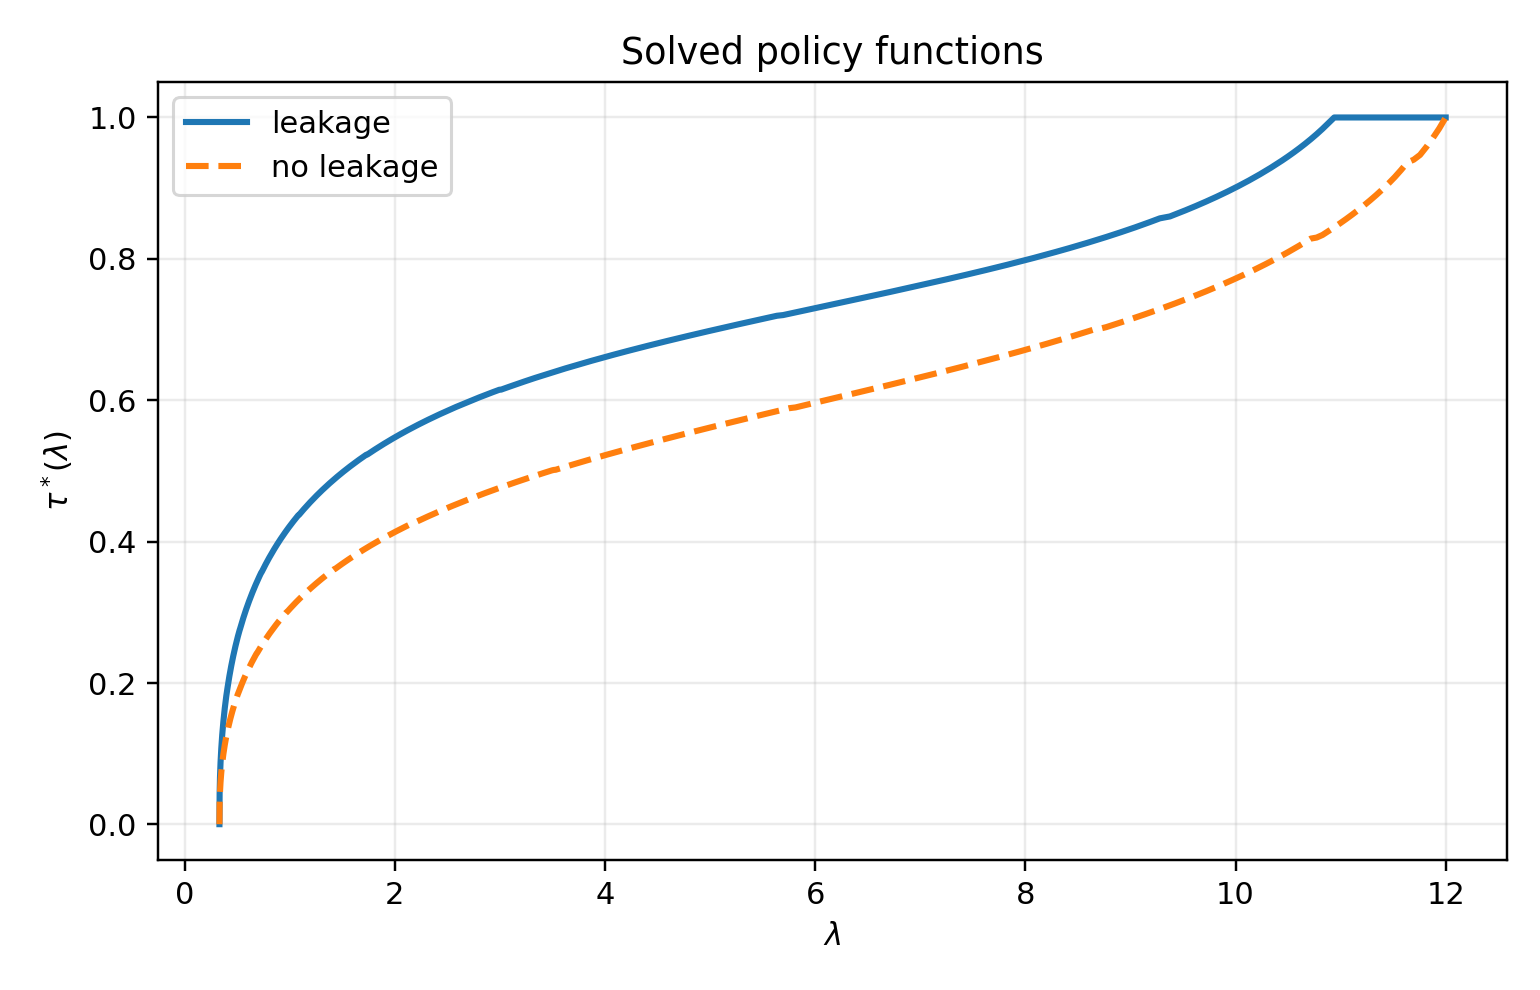


Displaying value_functions.png:


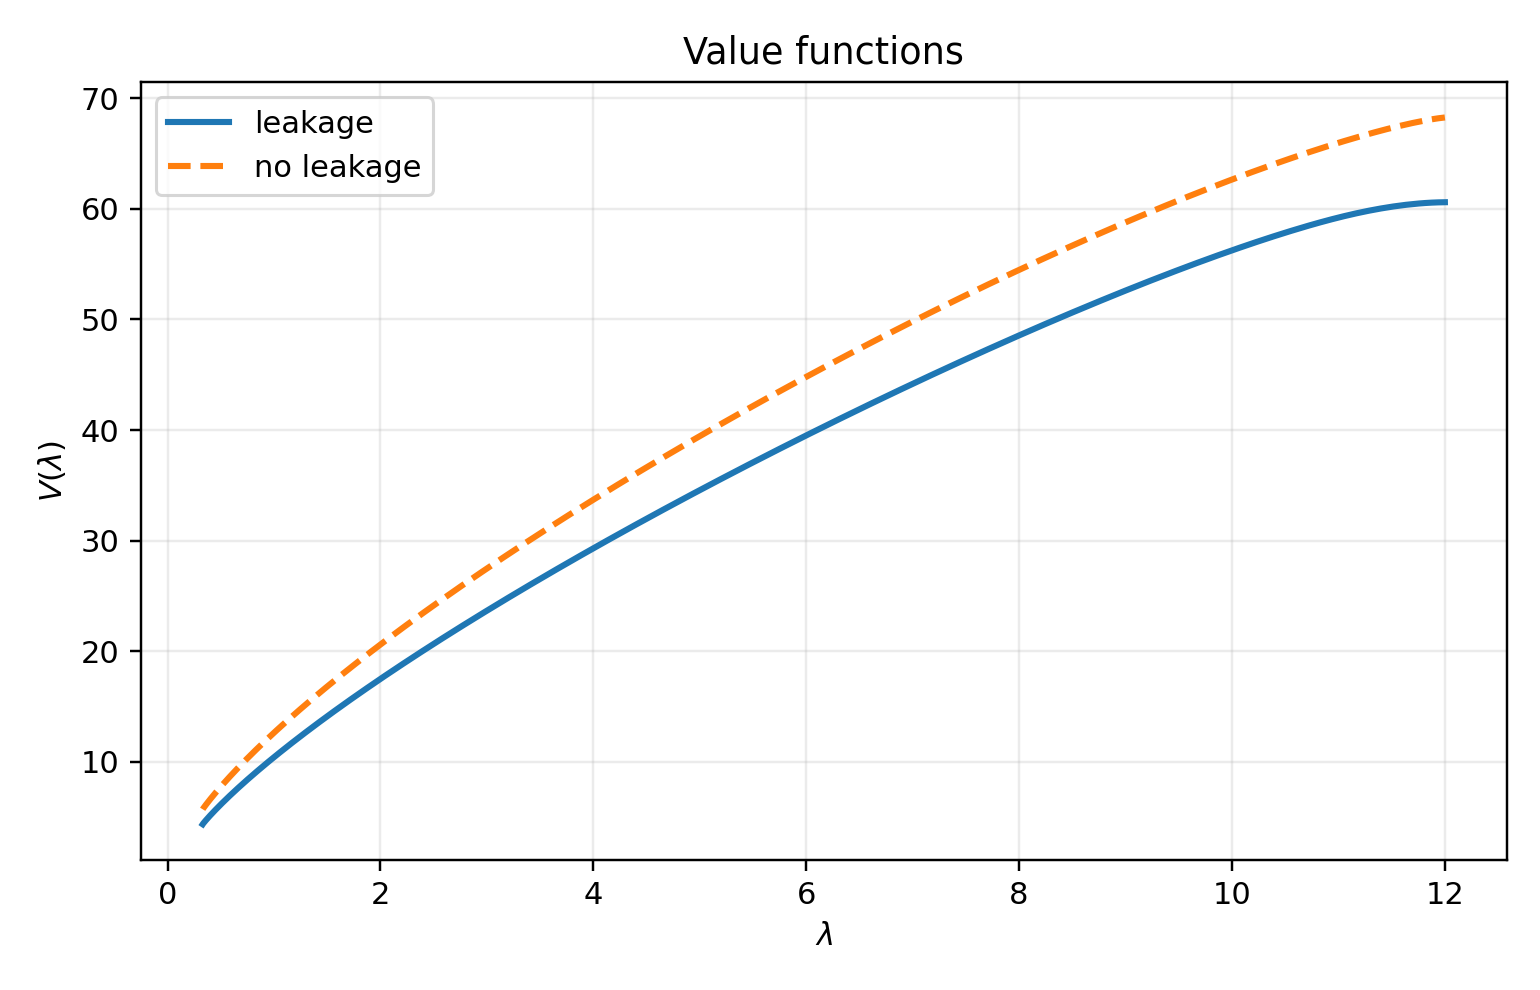


Displaying simulation_paths.png:


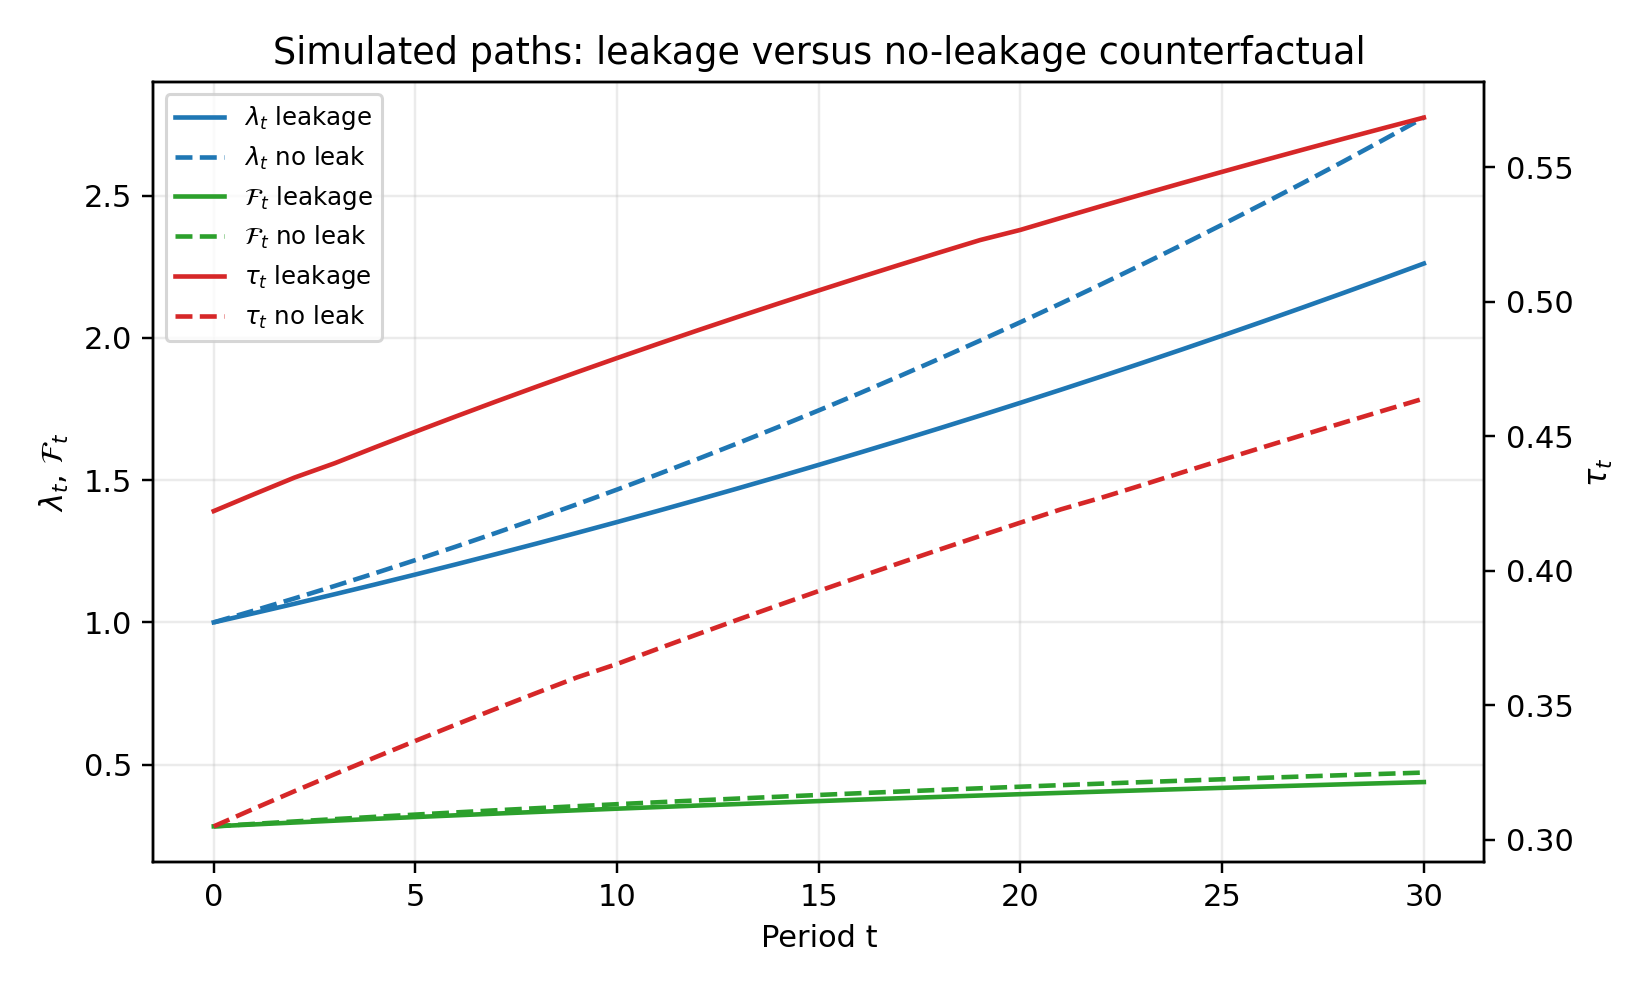

In [6]:
import os
from IPython.display import Image, display

# Run the main analysis to ensure the plots are generated
results = run_all(
    fast=False,
    refine=True,
    do_grid=True,
    do_calibration=True,
    do_oat=True,
    do_sigma_R=True,
    do_two_way=True,
    make_plots=True
)

# Path where plots are saved
plots_dir = OUT_DIR / "baseline_BG_net_external_only"

# Display the saved plots
plot_files = ["policy_functions.png", "value_functions.png", "simulation_paths.png"]
for plot_file in plot_files:
    plot_path = plots_dir / plot_file
    if plot_path.exists():
        print(f"\nDisplaying {plot_file}:")
        display(Image(filename=str(plot_path)))
    else:
        print(f"Could not find plot: {plot_file}")


Showing policy_functions.png:


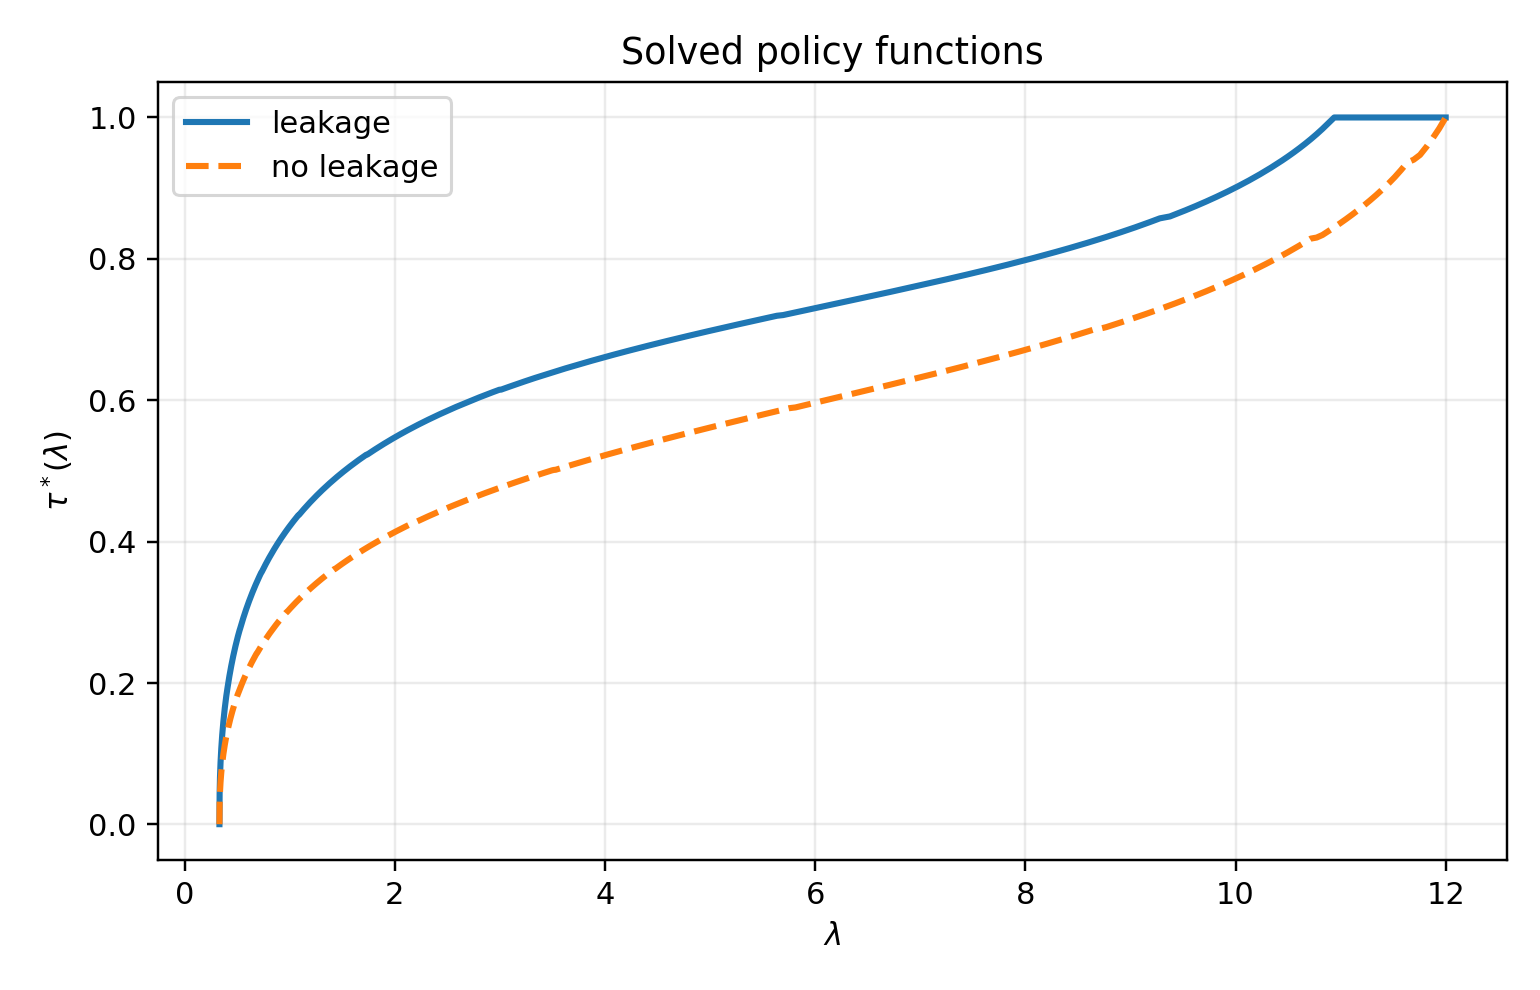


Showing value_functions.png:


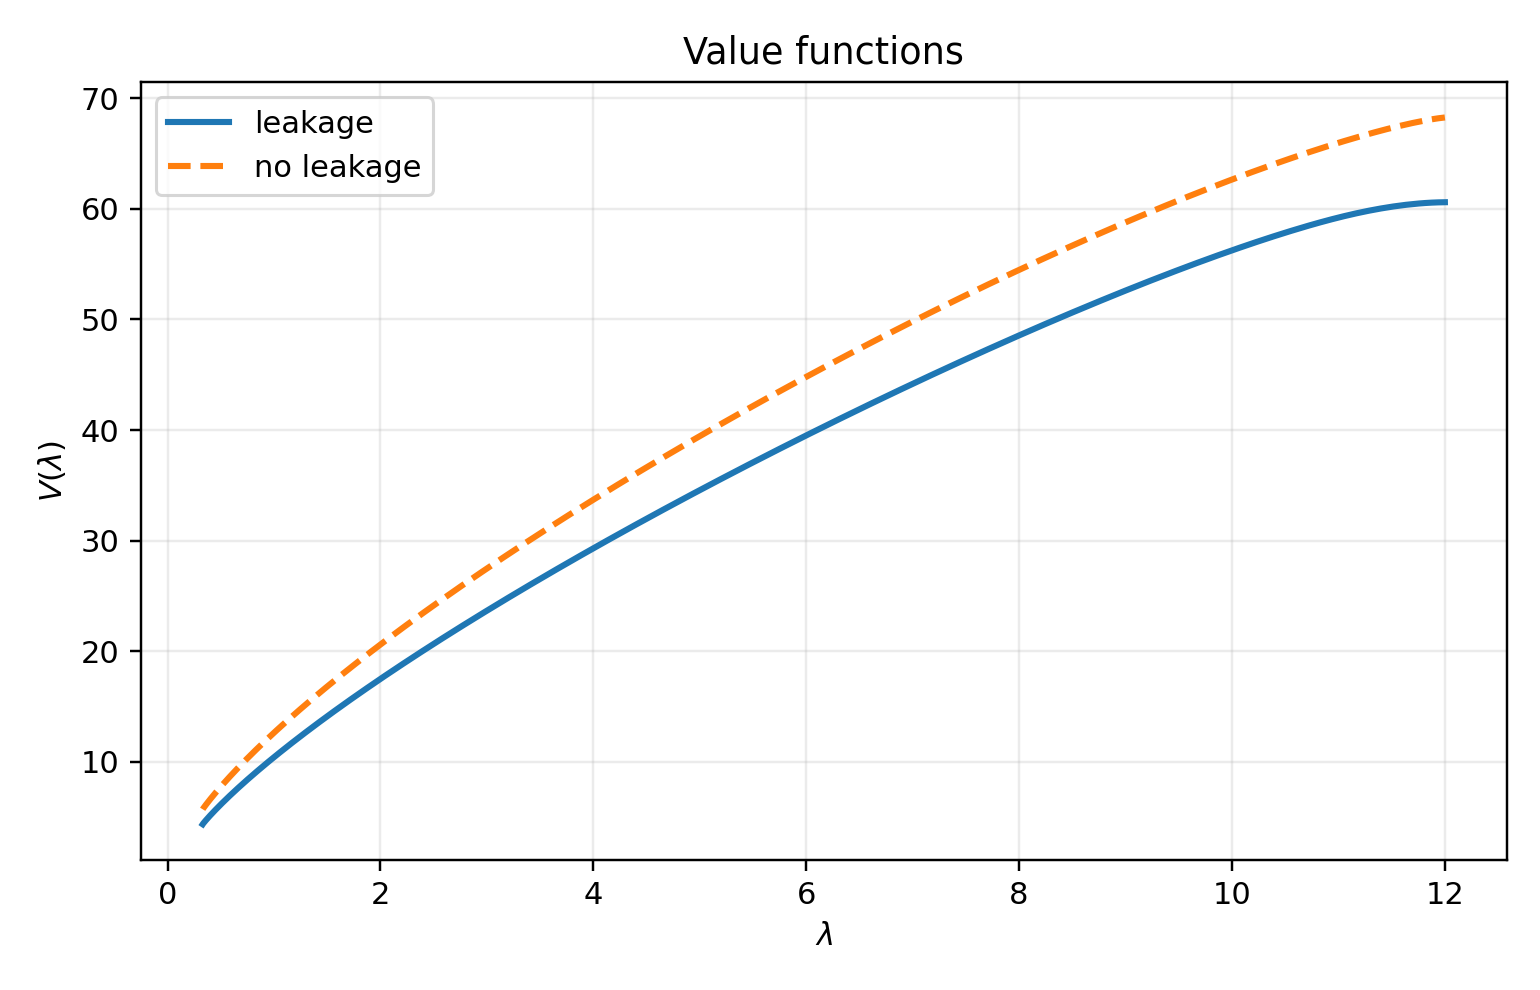


Showing simulation_paths.png:


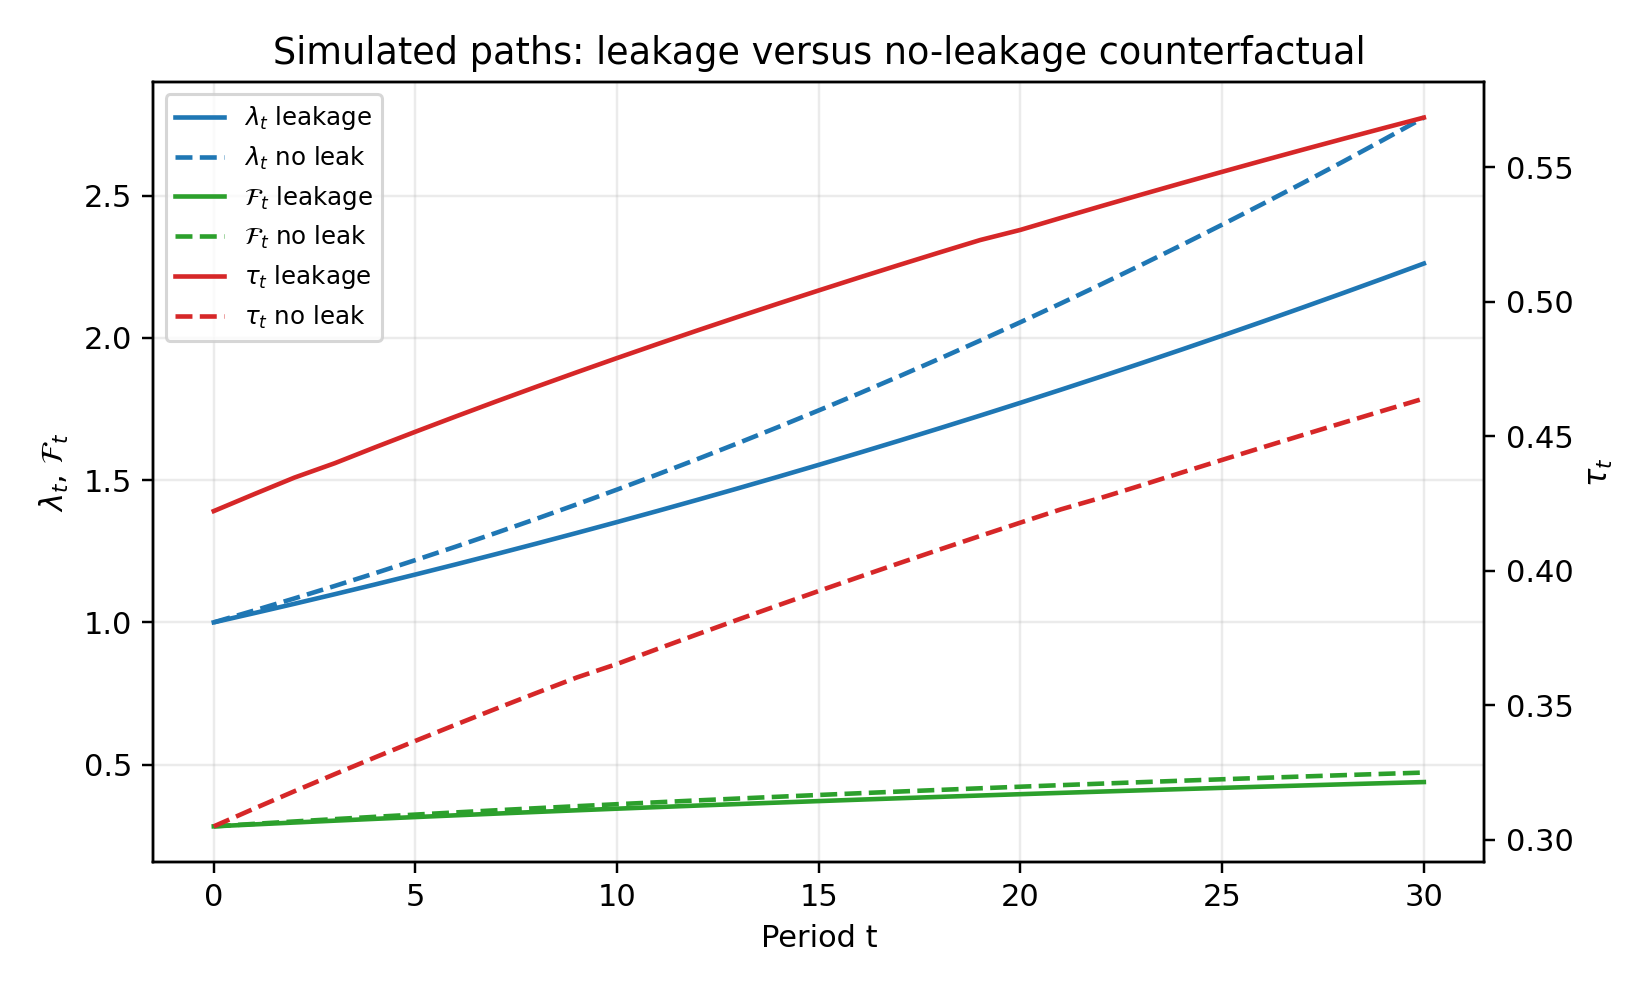

In [7]:
import os
from IPython.display import Image, display
from pathlib import Path

plots_dir = Path("bulgaria_refinement_sensitivity_outputs/baseline_BG_net_external_only")
plot_files = ["policy_functions.png", "value_functions.png", "simulation_paths.png"]

for plot_file in plot_files:
    plot_path = plots_dir / plot_file
    if plot_path.exists():
        print(f"\nShowing {plot_file}:")
        display(Image(filename=str(plot_path)))
    else:
        print(f"Plot not found: {plot_file}")